# Argus — Tiny grid detector `tiny_yolo_w1` (YOLO-style CNN, built from scratch)

Our own **single-shot object detector**, written layer by layer in Keras without Ultralytics.
It finds **eyes (open/closed), a yawning mouth and the head position** in a face crop. It's one
fully convolutional network that mixes **classification** (objectness + class per grid cell)
with **regression** (box centre and size per grid cell), the idea behind YOLO.

**Where it sits in Argus** (this is the model `src/cv-argus` deploys):

    camera frame → BlazeFace face crop → THIS DETECTOR → per-frame eye / yawn / head state
                                                       → IoU tracker + timed rules → severity → ESP32

It must run on a Raspberry Pi 5 CPU, so the targets are **≤ ~100k parameters, int8 TFLite,
grayscale input**. `tiny_yolo_w1` has about 46k.

**One model only.** Earlier versions of this notebook also trained a YOLOv1-style baseline
("step 1") and kept whichever scored higher on validation. The modern tiny YOLO won and is what
cv-argus runs, so the baseline, the winner-picking and the width ablations were removed (they
are in git history). This notebook trains exactly `tiny_yolo_w1`.

**How the notebook is laid out:**
1. **Setup and loading** (cells shared verbatim with notebooks 13 / 14).
2. **Part A, the dataset:** what we load, images per object, example images, histograms over the
   whole dataset, and correlations, all read with this model in mind (box sizes against the
   8 px grid cell, where objects land on the grid, head-pose labels).
3. **Shared evaluation, latency and the `tf.data` pipeline**, plus a preview of the training
   augmentation.
4. **Part B, the model:** the grid head, the architecture, **the maths behind every block**
   with resources, a layer-by-layer inspection (shapes, parameters, receptive field), and how
   the dataset maps onto the 20 × 20 grid.
5. **Part C, training:** the full setup in one table (loss, optimiser, LR schedule, early
   stopping, augmentation), the training run and its curves, then test evaluation float + int8.
6. **Part D, results:** per-class recall / precision / AP, confusion matrices over all labels,
   PR curves, and labelled-vs-predicted image comparisons (test, worst cases, training images,
   float vs int8).

**Reads:** `dataset/parts_det.zip`, built by `src/dataset/scripts/build_detection_dataset.py`.
It holds YOLO labels for `open_eye`, `closed_eye`, `yawn`, `head_straight` and `head_down` on
192 px face crops, plus MRL and Roboflow close-ups.

**Writes:**
- `models/parts_det/tiny_yolo_w1_<version>.keras` and `_int8.tflite` (the files cv-argus uses);
- `models/parts_det/tiny_yolo_w1_metrics.json`, read by notebook 14's comparison table;
- `models/parts_det/figures/`: every plot below, as PNG.

## Setup

**Getting the dataset in (Colab).** Upload `parts_det.zip`, built by
`src/dataset/scripts/build_detection_dataset.py`, **straight into the session**. Either drag it
into the Files panel (left sidebar → 📁 → upload, so it lands at `/content/parts_det.zip`), or
run the Loading cell and use the upload button it shows if the zip isn't found. Drive isn't
needed for the dataset.

**Keeping the results.** A Colab session's disk is wiped when it ends.
- With `USE_DRIVE = True` (the default), Drive is mounted only to save trained models and
  metrics to `MyDrive/Argus/models/parts_det/`. They survive the session, and notebook 14's
  comparison table can read all three notebooks' results.
- With `USE_DRIVE = False`, everything is saved under `/content/models/parts_det/` and the last
  cell zips it for download.

**Locally:** set `ARGUS_DET_ZIP`, and optionally `ARGUS_PROJECT_FOLDER` / `ARGUS_WORK_DIR`.
`ARGUS_SMOKE=1` turns every training run into a few-step smoke test on a small subset. It's used
to run the notebook end to end on a CPU before spending GPU time.

**This cell is shared verbatim by notebooks 12 / 13 / 14** so their numbers are comparable;
change it in all three or none.

In [ ]:
import os
import sys
import json
import time
import shutil
import zipfile
import datetime

import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
SMOKE = os.environ.get("ARGUS_SMOKE", "0") == "1"
USE_DRIVE = True          # Colab only: save models/metrics to Drive so they outlive the session

if IN_COLAB:
    WORK_DIR = "/content"
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        project_folder = "/content/drive/MyDrive/Argus"
    else:
        project_folder = "/content"
else:
    project_folder = os.environ.get("ARGUS_PROJECT_FOLDER", os.path.expanduser("~/argus-colab-mirror"))
    WORK_DIR = os.environ.get("ARGUS_WORK_DIR", "/tmp/argus_work")

models_folder = f"{project_folder}/models/parts_det"
# Where the dataset zip may be, in order: explicit env var, uploaded into the session, on Drive.
DET_ZIP_CANDIDATES = [p for p in (os.environ.get("ARGUS_DET_ZIP"), f"{WORK_DIR}/parts_det.zip",
                                  f"{project_folder}/dataset/parts_det.zip") if p]
os.makedirs(models_folder, exist_ok=True)
os.makedirs(WORK_DIR, exist_ok=True)
VERSION_STR = datetime.datetime.now().strftime("%Y%m%d_%H%M")

# Dataset contract (src/dataset/argus_dataset/config.py: DET_CLASSES, DET_IMG_SIZE = 192 stored).
CLASSES = ["open_eye", "closed_eye", "yawn", "head_straight", "head_down"]
NUM_CLASSES = len(CLASSES)
EYE_CLASSES, YAWN_CLASS, HEAD_CLASSES = (0, 1), 2, (3, 4)

IMG = 160                 # model input side (stored crops are 192 px, resized here)
VARIANT = "mix"           # "gray" | "ir" | "mix" (train: random gray/IR blend per image)
EVAL_VARIANT = "ir"       # what val/test images look like: the cabin camera is a Pi NoIR
INCLUDE_CLOSEUPS = True   # MRL + Roboflow eye/mouth close-ups (whole image = one box)
INCLUDE_PSEUDO_EYES = True  # images whose skipped eyes were pseudo-labelled from landmarks
CONF_THR = 0.25           # operating point for P/R, eye-state and head accuracy
SEED = 42
np.random.seed(SEED)
print(f"IN_COLAB={IN_COLAB} SMOKE={SMOKE} USE_DRIVE={USE_DRIVE}\nmodels -> {models_folder}")

Mounted at /content/drive
IN_COLAB=True SMOKE=False USE_DRIVE=True
models -> /content/drive/MyDrive/Argus/models/parts_det


## Loading the detection dataset

The zip is found in this order:
1. `ARGUS_DET_ZIP`;
2. `/content/parts_det.zip`, i.e. uploaded into the session;
3. `MyDrive/Argus/dataset/parts_det.zip`;
4. otherwise an upload button.

It's unzipped to local session disk once. Training reads the local files, never Drive's FUSE
mount: thousands of small reads off Drive time out, as `07`/`11` found.

The zip is YOLO format:
- `gray/` and `ir/`, each with `{train,valid,test}/{images,labels}`;
- `index.csv`, one row per source image with `status`, `kind`, `source`, `group_id` and `split`.

**Splits are by group:** an original image plus its augmented copies and near-duplicates, or one
MRL subject. They were assigned when the dataset was built. Never re-split by image here.

Each label line is `class cx cy w h`, normalised to 0–1.

**This cell is shared verbatim by notebooks 12 / 13 / 14.**

In [ ]:
LOCAL_DIR = f"{WORK_DIR}/parts_det"


def find_dataset_zip():
    for p in DET_ZIP_CANDIDATES:
        if os.path.isfile(p) and zipfile.is_zipfile(p):
            return p
    if IN_COLAB:   # not uploaded yet: show an upload button (Files panel drag-and-drop is faster for 371 MB)
        from google.colab import files
        print("parts_det.zip not found — choose it in the upload button below.")
        for name in files.upload():
            if name.endswith(".zip"):
                dest = f"{WORK_DIR}/parts_det.zip"
                if os.path.abspath(name) != dest:
                    shutil.move(name, dest)
                return dest
    raise FileNotFoundError(f"parts_det.zip not found in {DET_ZIP_CANDIDATES}")


if not os.path.isfile(f"{LOCAL_DIR}/index.csv"):
    DET_ZIP = find_dataset_zip()
    print(f"Extracting {DET_ZIP} -> {LOCAL_DIR}")
    with zipfile.ZipFile(DET_ZIP) as zf:
        zf.extractall(LOCAL_DIR)

index = pd.read_csv(f"{LOCAL_DIR}/index.csv", dtype=str, keep_default_na=False)
ok = index[index.status == "ok"].copy()
if not INCLUDE_CLOSEUPS:
    ok = ok[ok.kind != "closeup"]
if not INCLUDE_PSEUDO_EYES:
    ok = ok[ok.pseudo_eyes.isin(["", "0"])]


def read_labels(label_rel):
    """YOLO label file -> (classes int32 (n,), boxes float32 (n,4) as cx,cy,w,h)."""
    rows = [l.split() for l in open(f"{LOCAL_DIR}/{label_rel}").read().splitlines() if l.strip()]
    if not rows:
        return np.zeros(0, np.int32), np.zeros((0, 4), np.float32)
    a = np.array(rows, np.float32)
    return a[:, 0].astype(np.int32), a[:, 1:5]


splits = {}
for s in ("train", "valid", "test"):
    df = ok[ok.split == s].reset_index(drop=True)
    if SMOKE:   # a few images of every (source, kind) so every code path still runs
        df = (df.groupby(["source", "kind"], group_keys=False)
                .apply(lambda g: g.sample(min(len(g), 24), random_state=SEED)).reset_index(drop=True))
    labels = [read_labels(p) for p in df.label_path]
    df["classes"] = [c for c, _ in labels]
    df["boxes"] = [b for _, b in labels]
    splits[s] = df

summary = pd.DataFrame({
    s: {"images": len(d), **{c: int(sum(int((a == i).sum()) for a in d.classes))
                             for i, c in enumerate(CLASSES)}}
    for s, d in splits.items()})
print(summary)


def image_path(row, variant):
    return f"{LOCAL_DIR}/{row['gray_path'] if variant == 'gray' else row['ir_path']}"


def gts_for(df):
    """Ground truth per image as xyxy boxes, for the shared evaluation."""
    out = {}
    for r in df.itertuples():
        b = r.boxes
        out[r.image_id] = (np.c_[b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2,
                                 b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], r.classes)
    return out

Extracting /content/parts_det.zip -> /content/parts_det
               train  valid  test
images         27656   5815  5532
open_eye       25750   5659  5555
closed_eye     14124   2717  2618
yawn            1587    378   351
head_straight   5521   1105  1200
head_down        633    121   122


# Part A: The dataset we train on

Everything here reads the same `splits` the model trains on (Setup's filters applied; in
`ARGUS_SMOKE` mode it's the small smoke subset, otherwise the whole dataset). The point is not
generic statistics but the questions this detector raises:
- Is each class present often enough, in every split, for its AP to mean anything?
- How big are the objects compared with the model's **8 px grid cell** at `IMG = 160`?
- Where on the crop do objects land, and do several land in the same cell?
- What do gray and IR-simulated images look like, since training blends them?
- Where do the head labels come from, and how well does the pitch rule agree with humans?

Figures are saved under `models/parts_det/figures/`.

## A1. What we load

- **Accepted images per source and split.** Splits are by group (an original image + its
  augmented copies + near-duplicates, or one MRL subject), assigned at build time.
- **Kinds.** `face` = a square BlazeFace face crop, the input the Pi sees. `closeup` = an MRL eye
  photo or a Roboflow eye/mouth close-up whose single box is the whole image.
- **Why source images were rejected** (`index.csv`'s `reason`).
- **Where the head labels come from** (`head_source`). `human` is a person's head-pose label
  (e.g. `headpose-w4zuc`). `human_box` is the same, on a crop built around the human head box
  because BlazeFace missed the face. `landmarks` means the FaceLandmarker pitch rule. Zips built
  before head-pose sources have no such column; the cell skips it.

39003 accepted images (whole dataset)

Images per source and split:
split                       train  valid  test    All
project                                              
drowsiness-aunvg             1760    387   391   2538
drowsiness-axuoa              517    104   105    726
drowsiness-detection-luvay   1677    351   341   2369
drowsiness-detection-xsriz   2146    447   433   3026
drowsiness-driver-jhmld      4246    849   904   5999
drowsiness-hgjay             1316    284   271   1871
facial-movements-detection   1059    212   218   1489
headpose-w4zuc               2787    626   652   4065
mrl_eye                     12148   2555  2217  16920
All                         27656   5815  5532  39003 

Images per kind and split:
split    train  valid  test    All
kind                              
closeup  15464   3245  2878  21587
face     12192   2570  2654  17416
All      27656   5815  5532  39003 

Rejected source images: 12773 of 51776
project                   drowsiness-au

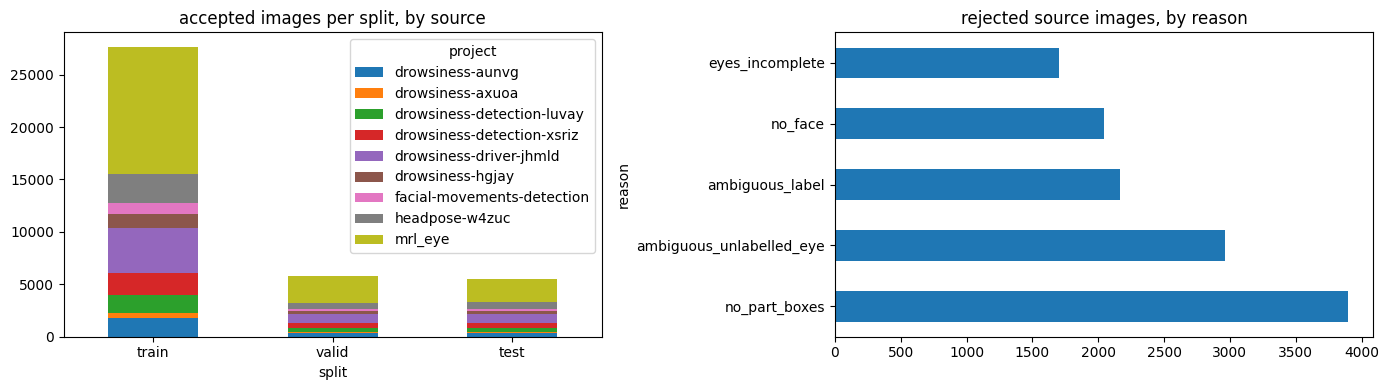

In [ ]:
import matplotlib.pyplot as plt
import cv2

FIG_DIR = f"{models_folder}/figures"
os.makedirs(FIG_DIR, exist_ok=True)
CLASS_COLORS = plt.cm.tab10(np.arange(NUM_CLASSES))[:, :3]


def savefig(fig, name):
    path = f"{FIG_DIR}/{name}_{VERSION_STR}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    print(f"-> {path}")


all_imgs = pd.concat([d.assign(split=s) for s, d in splits.items()], ignore_index=True)
print(f"{len(all_imgs)} accepted images ({'SMOKE subset' if SMOKE else 'whole dataset'})\n")
print("Images per source and split:")
print(pd.crosstab(all_imgs.project, all_imgs.split, margins=True)[list(splits) + ["All"]].to_string(), "\n")
print("Images per kind and split:")
print(pd.crosstab(all_imgs.kind, all_imgs.split, margins=True)[list(splits) + ["All"]].to_string(), "\n")

rej = index[index.status != "ok"]
print(f"Rejected source images: {len(rej)} of {len(index)}")
print(rej.groupby(["reason", "project"]).size().unstack(fill_value=0).to_string(), "\n")

if "head_source" in all_imgs.columns:
    heads = all_imgs[all_imgs.head_class != ""]
    print("Head boxes by class and label source:")
    print(pd.crosstab(heads.head_class, heads.head_source.replace("", "?"), margins=True).to_string(), "\n")
else:
    print("index.csv has no head_source column (zip built before head-pose sources).\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.crosstab(all_imgs.split, all_imgs.project).loc[list(splits)].plot.bar(
    ax=axes[0], stacked=True, rot=0, title="accepted images per split, by source")
rej.reason.str.split(":").str[0].value_counts().plot.barh(ax=axes[1], title="rejected source images, by reason")
plt.tight_layout(); savefig(fig, "a1_dataset_overview"); plt.show()

## A2. How many images contain each object

Box counts overstate eyes (two per face), so this counts **images**: an image with two open eyes
counts once for `open_eye`. Also shown: objects per image, and the most common label
combinations, i.e. what a typical training image asks the detector to find at once.

Images containing each object (39003 images):
split          train  valid  test    all  % of images  boxes
open_eye       16383   3728  3545  23656         60.7  36964
closed_eye     11431   2105  2018  15554         39.9  19459
yawn            1582    377   351   2310          5.9   2316
head_straight   5521   1105  1200   7826         20.1   7826
head_down        633    121   122    876          2.2    876 

Images containing each object, by source:
                            open_eye  closed_eye  yawn  head_straight  head_down
project                                                                         
drowsiness-aunvg                1383        1091   757           1115          3
drowsiness-axuoa                 499         233   499            291          5
drowsiness-detection-luvay      1282        1106   505            257          2
drowsiness-detection-xsriz      2191         894     0           1528        229
drowsiness-driver-jhmld         3661        2399   549    

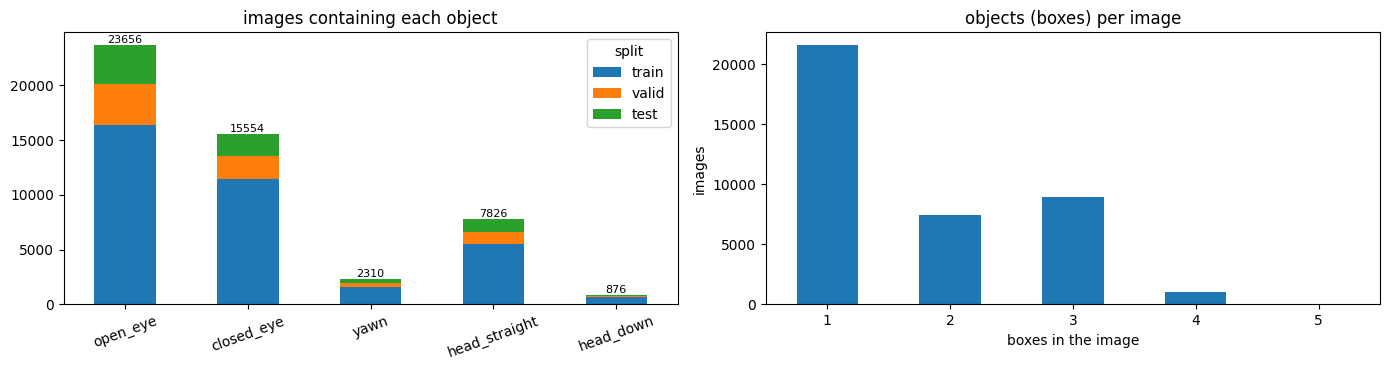

In [ ]:
for i, c in enumerate(CLASSES):
    all_imgs[c] = all_imgs.classes.apply(lambda a, i=i: bool((a == i).any()))
img_per_class = all_imgs.groupby("split")[CLASSES].sum().T[list(splits)]
img_per_class["all"] = img_per_class.sum(axis=1)
img_per_class["% of images"] = (100 * img_per_class["all"] / len(all_imgs)).round(1)
box_per_class = pd.Series({c: int(sum(int((a == i).sum()) for a in all_imgs.classes)) for i, c in enumerate(CLASSES)})
img_per_class["boxes"] = box_per_class
print(f"Images containing each object ({len(all_imgs)} images):")
print(img_per_class.to_string(), "\n")
print("Images containing each object, by source:")
print(all_imgs.groupby("project")[CLASSES].sum().astype(int).to_string(), "\n")

n_obj = all_imgs.classes.apply(len)
combo = all_imgs.classes.apply(lambda a: " + ".join(CLASSES[k] for k in sorted(set(a.tolist()))) or "(none)")
print("Most common label combinations per image:")
print(combo.value_counts().head(12).rename_axis("labels in the image").rename("images").to_string(), "\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
img_per_class[list(splits)].plot.bar(ax=axes[0], rot=20, stacked=True, title="images containing each object")
for k, v in enumerate(img_per_class["all"]):
    axes[0].text(k, v, str(int(v)), ha="center", va="bottom", fontsize=8)
n_obj.value_counts().sort_index().plot.bar(ax=axes[1], rot=0, title="objects (boxes) per image")
axes[1].set_xlabel("boxes in the image"); axes[1].set_ylabel("images")
plt.tight_layout(); savefig(fig, "a2_images_per_object"); plt.show()

## A3. Example images: labels, gray vs IR, face crops vs close-ups

Three views of what the model is fed:
1. **Labelled examples per class**, with **every** ground-truth box drawn. They show label
   problems that a table can't: a skipped eye (it would be learned as background), a head box
   on the wrong person, a `head_down` that is really a head turned away.
2. **The same image as gray and as IR-simulated.** With `VARIANT = "mix"` every training image is
   a random blend of the two. Evaluation uses `EVAL_VARIANT` (IR, like the Pi NoIR camera).
3. **One row per source**, mixing face crops and close-ups, to show how different the sources
   look.

The chosen image ids are written to `labelled_examples_<version>.csv`.

-> /content/drive/MyDrive/Argus/models/parts_det/figures/labelled_examples_20261020_2335.png


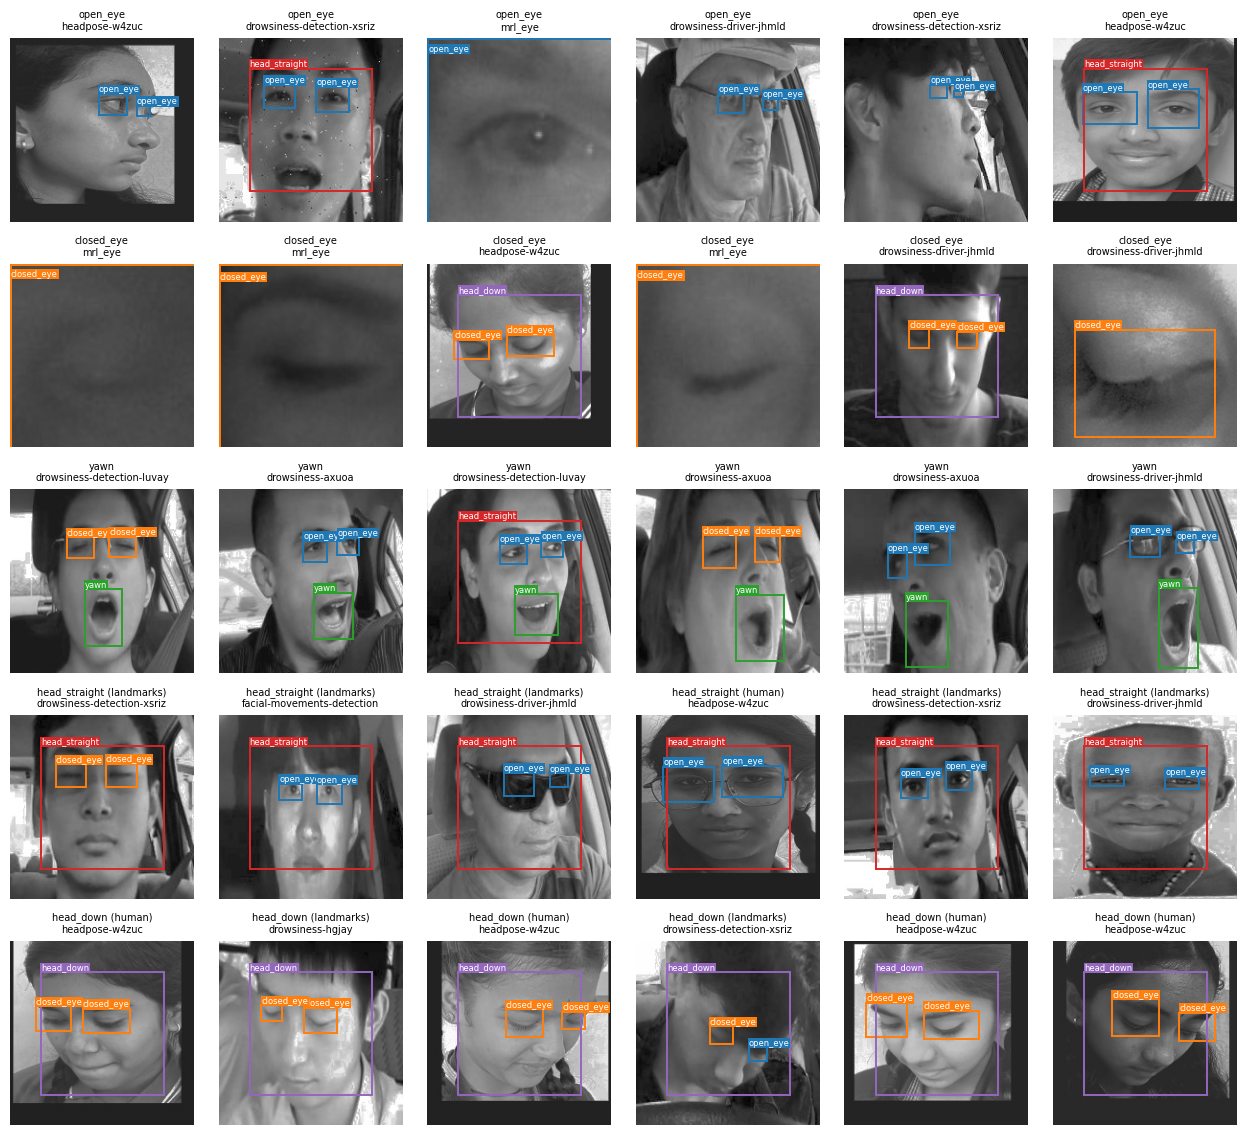

/tmp/ipykernel_1734/2887653981.py:51: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pick = faces.groupby("project", group_keys=False).apply(lambda g: g.sample(min(1, len(g)), random_state=SEED))


-> /content/drive/MyDrive/Argus/models/parts_det/figures/a3_gray_vs_ir_20261020_2335.png


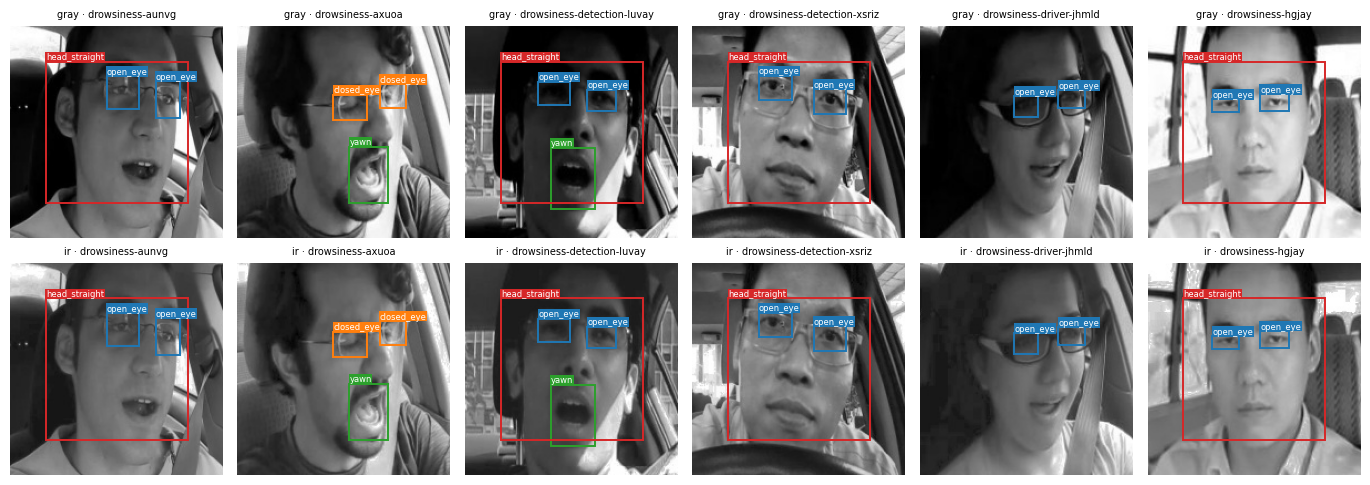

-> /content/drive/MyDrive/Argus/models/parts_det/figures/a3_sources_20261020_2335.png


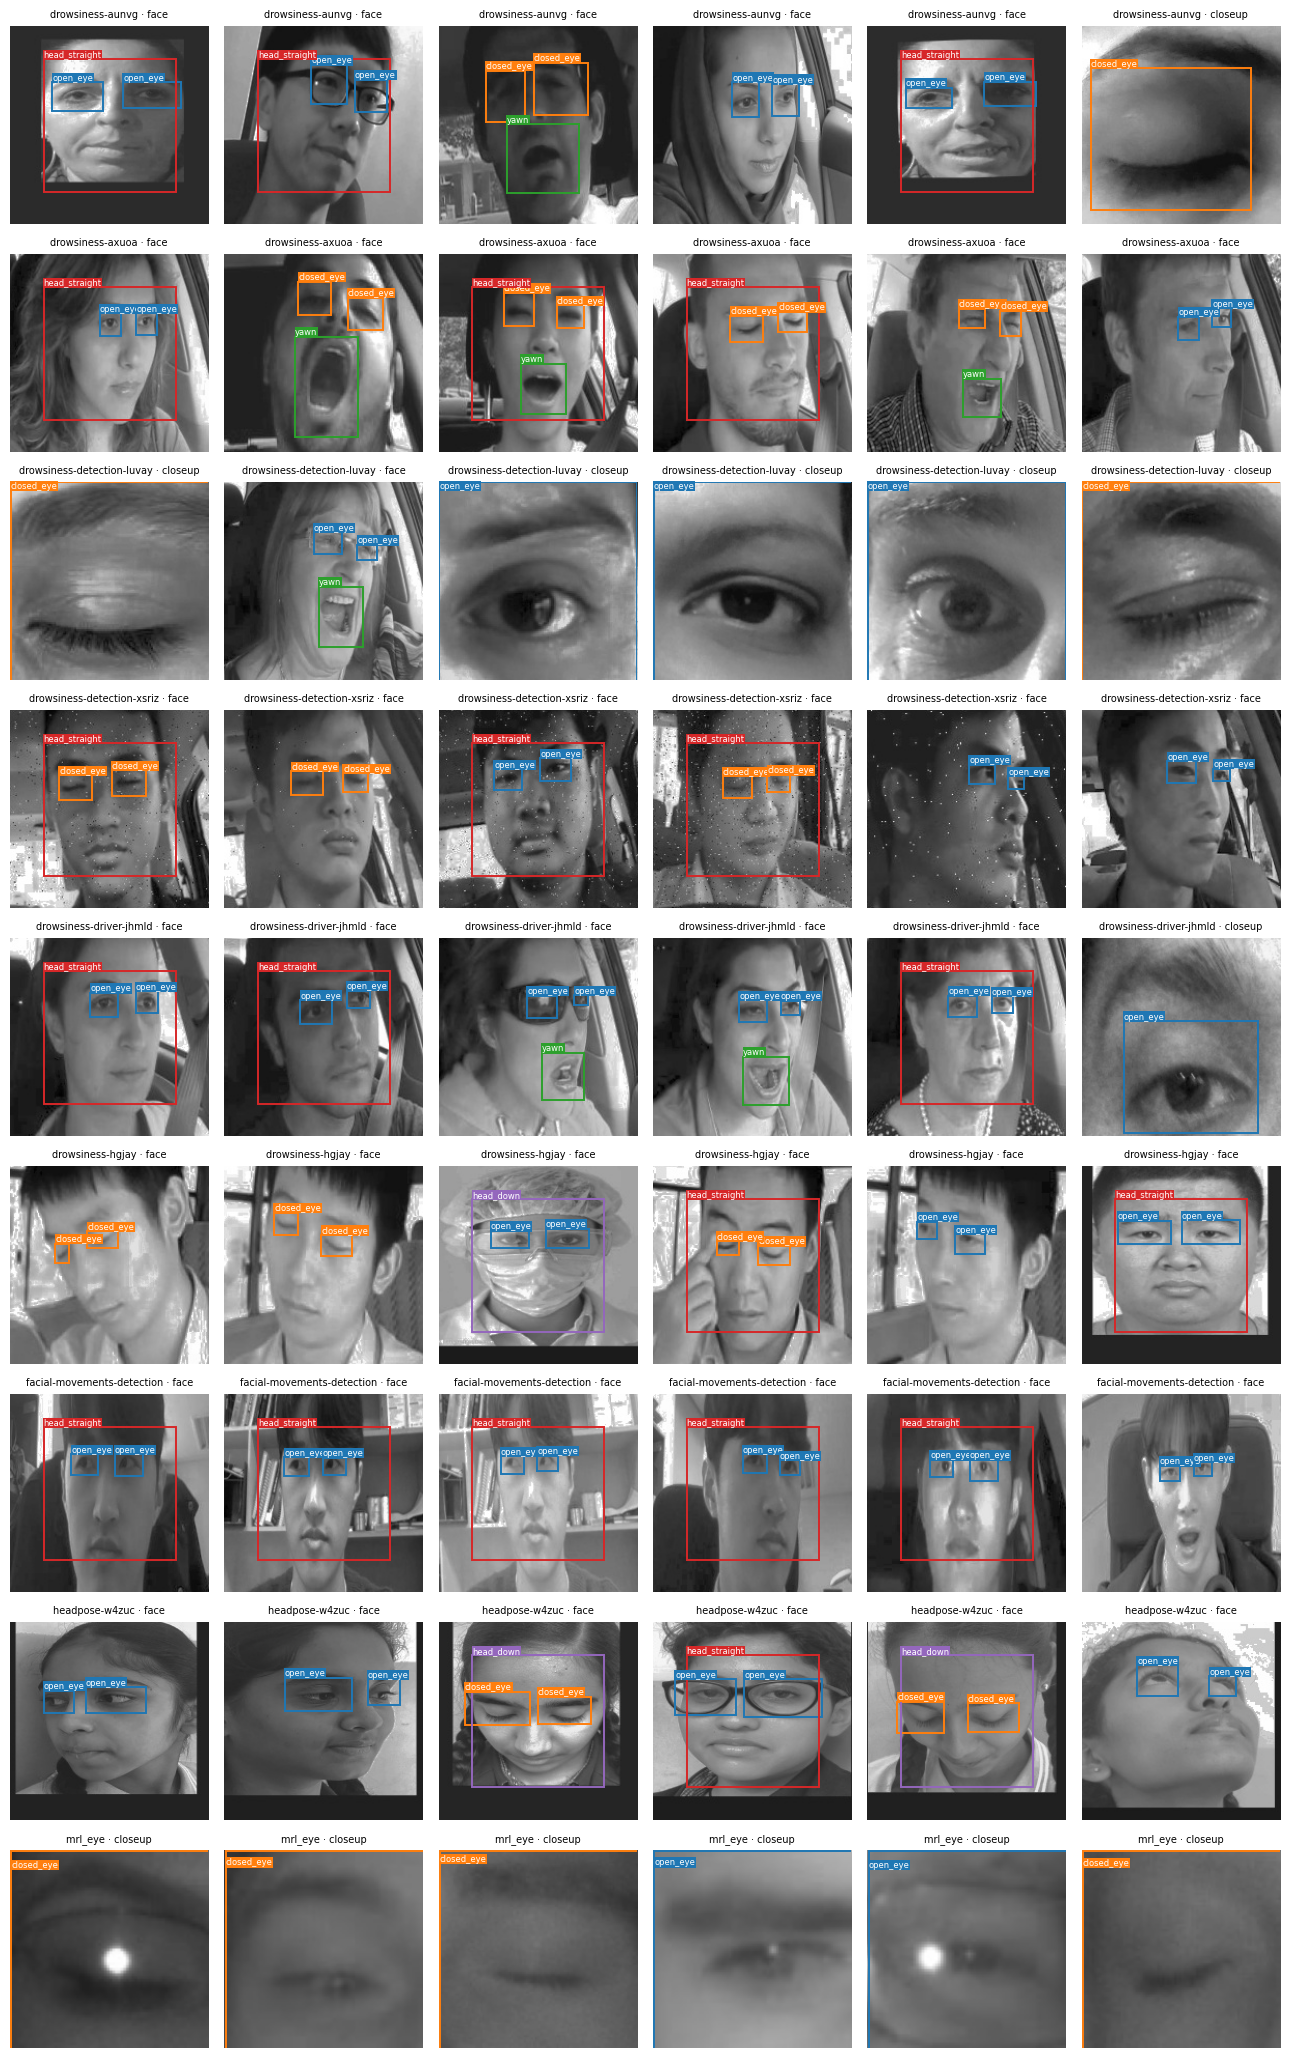

In [ ]:
N_EXAMPLES = 6     # images per class


def load_rgb(row, variant=EVAL_VARIANT):
    im = cv2.imread(image_path(row, variant), cv2.IMREAD_GRAYSCALE)
    return cv2.cvtColor(im, cv2.COLOR_GRAY2RGB)


def draw_boxes(ax, img, xyxy, classes, scores=None, title=""):
    """Boxes in normalised xyxy on `img`, coloured by class, with class (and score) text."""
    ax.imshow(img)
    H, W = img.shape[:2]
    for k, (b, c) in enumerate(zip(xyxy, classes)):
        x0, y0, x1, y1 = b[0] * W, b[1] * H, b[2] * W, b[3] * H
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=1.4, color=CLASS_COLORS[c]))
        txt = CLASSES[c] if scores is None else f"{CLASSES[c]} {scores[k]:.2f}"
        ax.text(x0, max(y0 - 2, 6), txt, fontsize=6, color="white",
                bbox=dict(facecolor=CLASS_COLORS[c], pad=0.5, lw=0))
    ax.set_title(title, fontsize=7)
    ax.axis("off")


def gt_xyxy(row):
    b = row["boxes"]
    return np.c_[b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2]


train_df = splits["train"]
fig, axes = plt.subplots(NUM_CLASSES, N_EXAMPLES, figsize=(2.1 * N_EXAMPLES, 2.3 * NUM_CLASSES))
chosen = []
for i, c in enumerate(CLASSES):
    cand = train_df[train_df.classes.apply(lambda a: bool((a == i).any()))]
    pick = cand.sample(min(N_EXAMPLES, len(cand)), random_state=SEED) if len(cand) else cand
    for j in range(N_EXAMPLES):
        ax = axes[i, j]
        if j >= len(pick):
            ax.axis("off")
            if j == 0:
                ax.text(0.5, 0.5, f"no {c} boxes\nin this split", ha="center", va="center", fontsize=9)
            continue
        r = pick.iloc[j]
        who = f" ({r['head_source']})" if i in HEAD_CLASSES and r.get("head_source") else ""
        draw_boxes(ax, load_rgb(r), gt_xyxy(r), r["classes"], title=f"{c}{who}\n{r['project']}")
        chosen.append({"class": c, "image_id": r["image_id"], "project": r["project"],
                       "split": "train", "path": image_path(r, EVAL_VARIANT)})
plt.tight_layout(); savefig(fig, "labelled_examples"); plt.show()
pd.DataFrame(chosen).to_csv(f"{FIG_DIR}/labelled_examples_{VERSION_STR}.csv", index=False)

# Same image, gray vs IR-simulated
faces = train_df[train_df.kind == "face"]
pick = faces.groupby("project", group_keys=False).apply(lambda g: g.sample(min(1, len(g)), random_state=SEED))
pick = pick.head(6)
fig, axes = plt.subplots(2, max(len(pick), 1), figsize=(2.3 * max(len(pick), 1), 5), squeeze=False)
for j, (_, r) in enumerate(pick.iterrows()):
    for k, v in enumerate(("gray", "ir")):
        draw_boxes(axes[k, j], load_rgb(r, v), gt_xyxy(r), r["classes"], title=f"{v} · {r['project']}")
plt.tight_layout(); savefig(fig, "a3_gray_vs_ir"); plt.show()

# One row per source: what each source looks like (face crops and close-ups)
srcs = sorted(all_imgs.project.unique())
fig, axes = plt.subplots(len(srcs), 6, figsize=(13, 2.3 * len(srcs)), squeeze=False)
for i, p in enumerate(srcs):
    sub = all_imgs[all_imgs.project == p]
    sub = sub.sample(min(6, len(sub)), random_state=SEED)
    for j in range(6):
        if j >= len(sub):
            axes[i, j].axis("off"); continue
        r = sub.iloc[j]
        draw_boxes(axes[i, j], load_rgb(r), gt_xyxy(r), r["classes"], title=f"{p} · {r['kind']}")
plt.tight_layout(); savefig(fig, "a3_sources"); plt.show()

## A4. Histograms over the whole dataset

- **Pixel intensity, gray vs IR, per source.** The cabin camera is a Pi NoIR. If one source's
  intensities sit far from the others, the model can learn "which dataset" instead of "which
  eye state". The IR variant is histogram-matched toward MRL's real IR, so its curves should sit
  closer together.
- **Box size in pixels at the model input** (`IMG = 160`), per class. The dashed line is the
  model's grid cell (`GRID_STRIDE = 8` px). Objects much smaller than a cell are hard to
  localise.
  Face crops only: a close-up's box is the whole image (160 px), and it would swamp the plot.
  Expect the **head boxes to be one fixed size (≈ 107 px)**. The crop is built as 1.5× the
  BlazeFace face box, and the head box *is* that face box, so `head_straight` / `head_down` is
  really a classification of the whole face, not a localisation problem. All the localisation
  difficulty is in the eyes (≈ 20 px, under 3 grid cells) and the mouth.
- **Box aspect ratio** (width / height), per class. The head is anchor-free, so it regresses
  w and h directly; one regression covers every shape.
- **Box centres**, binned on the model's own 20 × 20 grid, per class: where each object lands.
- **Head pitch / yaw** from FaceLandmarker, coloured by `head_class`, with the dataset's pitch
  thresholds (`src/dataset/argus_dataset/config.py`: `HEAD_STRAIGHT_PITCH_DEG = 10`,
  `HEAD_DOWN_PITCH_DEG = 20`, `HEAD_STRAIGHT_YAW_DEG = 25`; positive pitch = looking down).

-> /content/drive/MyDrive/Argus/models/parts_det/figures/a4_pixel_intensity_20261020_2335.png


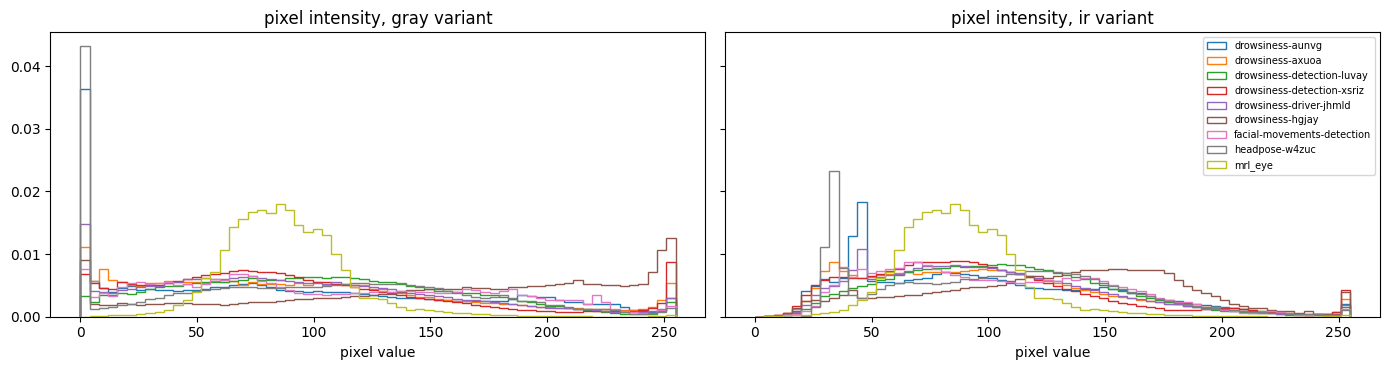

-> /content/drive/MyDrive/Argus/models/parts_det/figures/a4_box_geometry_20261020_2335.png


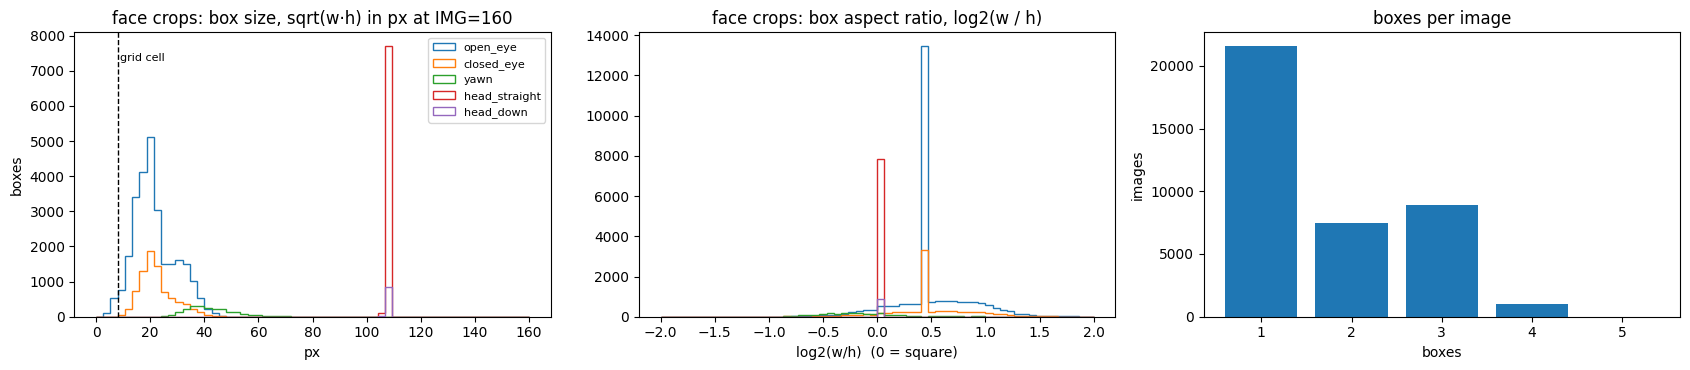

Box size in px at the model input, per class (face crops only):
                 count   mean  std    min    10%    50%    90%    max
class                                                                
closed_eye      8066.0   22.5  6.7    7.5   15.5   21.2   32.2  103.1
head_down        876.0  106.7  0.0  106.4  106.7  106.7  106.7  106.7
head_straight   7826.0  106.7  0.0  106.0  106.7  106.7  106.7  106.7
open_eye       26842.0   21.6  8.1    2.6   12.9   20.1   33.2  132.2
yawn            2238.0   42.7  8.8   24.2   32.8   41.3   54.8   79.1 

-> /content/drive/MyDrive/Argus/models/parts_det/figures/a4_centre_heatmaps_20261020_2335.png


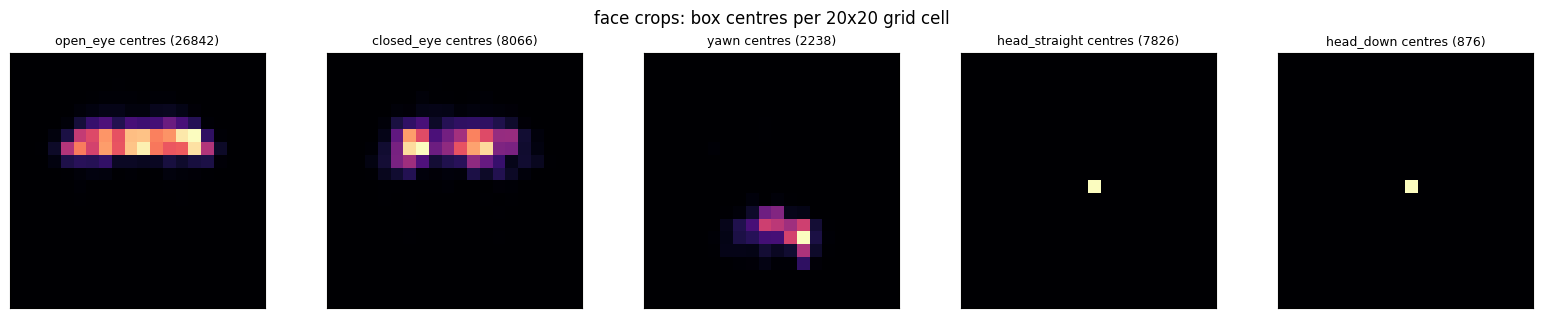

-> /content/drive/MyDrive/Argus/models/parts_det/figures/a4_head_pose_20261020_2335.png


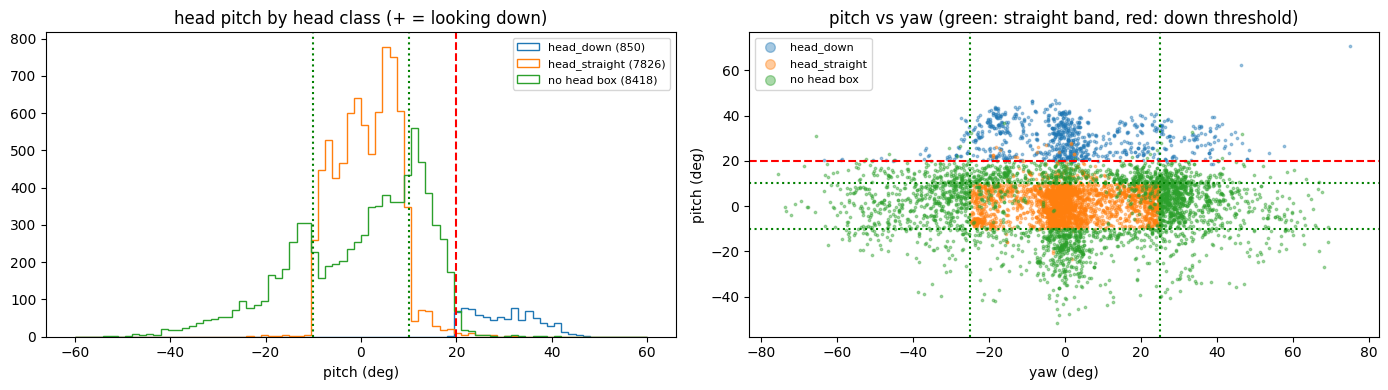

In [ ]:
CELL_PX = 8                      # = GRID_STRIDE in the model cell (stride-8 grid at IMG = 160)
GRID_CELLS = IMG // CELL_PX
HEAD_STRAIGHT_PITCH_DEG, HEAD_DOWN_PITCH_DEG, HEAD_STRAIGHT_YAW_DEG = 10, 20, 25   # dataset config

# Pixel intensity, gray vs IR, per source (a sample of images per source)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for p, sub in all_imgs.groupby("project"):
    sub = sub.sample(min(150 if not SMOKE else 20, len(sub)), random_state=SEED)
    for ax, v in zip(axes, ("gray", "ir")):
        px = np.concatenate([cv2.imread(image_path(r, v), cv2.IMREAD_GRAYSCALE).ravel()[::7]
                             for _, r in sub.iterrows()])
        ax.hist(px, bins=64, range=(0, 255), density=True, histtype="step", lw=1.4, label=p)
for ax, v in zip(axes, ("gray", "ir")):
    ax.set(title=f"pixel intensity, {v} variant", xlabel="pixel value")
axes[1].legend(fontsize=7)
plt.tight_layout(); savefig(fig, "a4_pixel_intensity"); plt.show()

# Box geometry per class, in model-input pixels
rows = []
for cl, bx, kind in zip(all_imgs.classes, all_imgs.boxes, all_imgs.kind):
    for c, b in zip(cl, bx):
        rows.append({"class": CLASSES[c], "kind": kind, "cx": b[0], "cy": b[1],
                     "w_px": b[2] * IMG, "h_px": b[3] * IMG,
                     "size_px": float(np.sqrt(b[2] * b[3])) * IMG, "aspect": b[2] / max(b[3], 1e-6)})
geo = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for i, c in enumerate(CLASSES):
    g = geo[(geo["class"] == c) & (geo.kind == "face")]   # close-ups are whole-image boxes
    if len(g):
        axes[0].hist(g.size_px, bins=60, range=(0, IMG), histtype="step", lw=1.5, color=CLASS_COLORS[i], label=c)
        axes[1].hist(np.log2(g.aspect), bins=60, range=(-2, 2), histtype="step", lw=1.5, color=CLASS_COLORS[i], label=c)
axes[0].axvline(CELL_PX, ls="--", c="k", lw=1); axes[0].text(CELL_PX + 1, axes[0].get_ylim()[1] * 0.9, "grid cell", fontsize=8)
axes[0].set(title=f"face crops: box size, sqrt(w·h) in px at IMG={IMG}", xlabel="px", ylabel="boxes")
axes[1].set(title="face crops: box aspect ratio, log2(w / h)", xlabel="log2(w/h)  (0 = square)")
axes[0].legend(fontsize=8)
n_box = all_imgs.classes.apply(len)
axes[2].bar(*np.unique(n_box, return_counts=True)); axes[2].set(title="boxes per image", xlabel="boxes", ylabel="images")
plt.tight_layout(); savefig(fig, "a4_box_geometry"); plt.show()
print("Box size in px at the model input, per class (face crops only):")
print(geo[geo.kind == "face"].groupby("class").size_px.describe(percentiles=[.1, .5, .9]).round(1).to_string(), "\n")

# Where object centres land on the 20 x 20 grid
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(3.2 * NUM_CLASSES, 3.2))
for i, c in enumerate(CLASSES):
    g = geo[(geo["class"] == c) & (geo.kind == "face")]
    h, _, _ = np.histogram2d(g.cy, g.cx, bins=GRID_CELLS, range=[[0, 1], [0, 1]])
    axes[i].imshow(h, cmap="magma"); axes[i].set_title(f"{c} centres ({len(g)})", fontsize=9)
    axes[i].set_xticks([]); axes[i].set_yticks([])
fig.suptitle(f"face crops: box centres per {GRID_CELLS}x{GRID_CELLS} grid cell"); plt.tight_layout()
savefig(fig, "a4_centre_heatmaps"); plt.show()

# Head pitch / yaw (FaceLandmarker), coloured by head class
pose = all_imgs[(all_imgs.pitch != "") & (all_imgs.kind == "face")].copy()
if len(pose):
    pose["pitch"], pose["yaw"] = pose.pitch.astype(float), pose.yaw.astype(float)
    pose["head"] = pose.head_class.replace("", "no head box")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for name, g in pose.groupby("head"):
        axes[0].hist(g.pitch, bins=80, range=(-60, 60), histtype="step", lw=1.5, label=f"{name} ({len(g)})")
        s = g.sample(min(len(g), 3000), random_state=SEED)
        axes[1].scatter(s.yaw, s.pitch, s=3, alpha=0.4, label=name)
    for v in (HEAD_STRAIGHT_PITCH_DEG, -HEAD_STRAIGHT_PITCH_DEG):
        axes[0].axvline(v, ls=":", c="g"); axes[1].axhline(v, ls=":", c="g")
    axes[0].axvline(HEAD_DOWN_PITCH_DEG, ls="--", c="r"); axes[1].axhline(HEAD_DOWN_PITCH_DEG, ls="--", c="r")
    for v in (HEAD_STRAIGHT_YAW_DEG, -HEAD_STRAIGHT_YAW_DEG):
        axes[1].axvline(v, ls=":", c="g")
    axes[0].set(title="head pitch by head class (+ = looking down)", xlabel="pitch (deg)"); axes[0].legend(fontsize=8)
    axes[1].set(title="pitch vs yaw (green: straight band, red: down threshold)", xlabel="yaw (deg)", ylabel="pitch (deg)")
    axes[1].legend(fontsize=8, markerscale=4)
    plt.tight_layout(); savefig(fig, "a4_head_pose"); plt.show()

## A5. Correlations and what they mean for the model

- **Which objects appear together** (face crops only, since close-ups carry one box). Left: the
  φ (phi) correlation between "image contains A" and "image contains B", i.e. Pearson on 0/1
  presence. Right: the conditional rate P(B | A), how often B is in an image that has A. A
  detector can exploit co-occurrence as a shortcut. For example, if `yawn` almost always comes
  with `open_eye`, then closed eyes on a yawning face are rare in training.
- **Box size by class**: a box plot of the same pixel sizes as A4. Overlapping ranges between
  `open_eye` and `closed_eye` are expected; the two must be told apart by *content*, not size.
- **Human head label vs. the pitch rule.** Where a person labelled the head pose, how often does
  the landmark pitch rule (used for every other source) agree? Disagreement means the
  pitch-labelled heads in the older sources carry label noise.
- **How noisy each test number is.** A recall measured on `n` boxes has a 95% interval of about
  ±1.96·√(p(1−p)/n), so at p = 0.5 that's ±0.98/√n. Rare classes give wide intervals; read their
  AP with that in mind.

-> /content/drive/MyDrive/Argus/models/parts_det/figures/a5_cooccurrence_20261020_2335.png


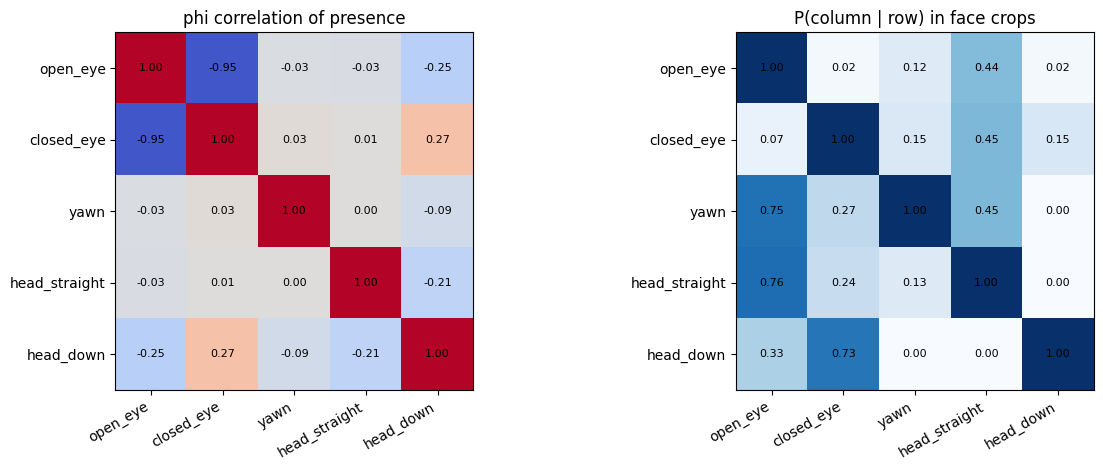

-> /content/drive/MyDrive/Argus/models/parts_det/figures/a5_size_by_class_20261020_2335.png


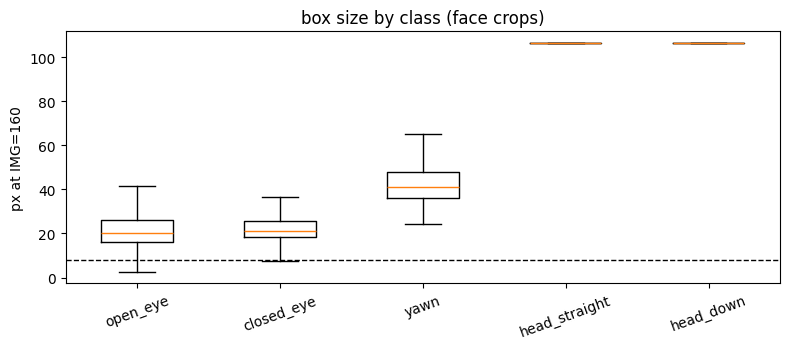

Human head label (rows) vs. what the landmark pitch rule says (columns):
lm_head_class     head_down  head_straight  none (ambiguous band)   All
head_class                                                             
head_down               412              0                     33   445
head_straight            35            549                    303   887
none (turned/up)         75            444                   2083  2602
All                     522            993                   2419  3934 

-> /content/drive/MyDrive/Argus/models/parts_det/figures/a5_human_vs_pitch_20261020_2335.png


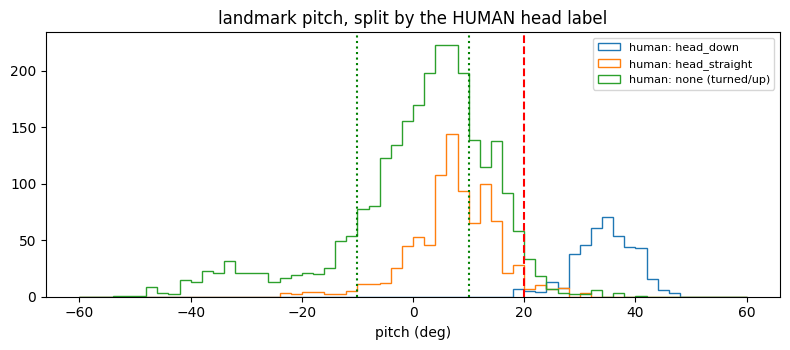

How precise each per-class test number can be:
               test boxes  ±95% on a recall near 0.5
open_eye             5555                      0.013
closed_eye           2618                      0.019
yawn                  351                      0.052
head_straight        1200                      0.028
head_down             122                      0.089


In [ ]:
face_imgs = all_imgs[all_imgs.kind == "face"]
X = face_imgs[CLASSES].to_numpy(float)
present = X.sum(0) > 0
phi = np.full((NUM_CLASSES, NUM_CLASSES), np.nan)
if len(X) > 1:
    with np.errstate(invalid="ignore", divide="ignore"):
        phi = np.corrcoef(X.T)
cond = (X.T @ X) / np.maximum(X.sum(0)[:, None], 1)      # row A, column B: P(B | A)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, M, title, lim in ((axes[0], phi, "phi correlation of presence", (-1, 1)),
                          (axes[1], cond, "P(column | row) in face crops", (0, 1))):
    ax.imshow(np.nan_to_num(M), cmap="coolwarm" if lim[0] < 0 else "Blues", vmin=lim[0], vmax=lim[1])
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, "–" if np.isnan(M[i, j]) else f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASSES, rotation=30, ha="right"); ax.set_yticklabels(CLASSES); ax.set_title(title)
plt.tight_layout(); savefig(fig, "a5_cooccurrence"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
data = [geo[(geo["class"] == c) & (geo.kind == "face")].size_px for c in CLASSES]
ax.boxplot([d if len(d) else [np.nan] for d in data], showfliers=False)
ax.set_xticks(range(1, NUM_CLASSES + 1)); ax.set_xticklabels(CLASSES, rotation=20)
ax.axhline(CELL_PX, ls="--", c="k", lw=1); ax.set(title="box size by class (face crops)", ylabel=f"px at IMG={IMG}")
plt.tight_layout(); savefig(fig, "a5_size_by_class"); plt.show()

if "head_source" in all_imgs.columns and (all_imgs.head_source == "human").any():
    hum = all_imgs[all_imgs.head_source == "human"].copy()
    print("Human head label (rows) vs. what the landmark pitch rule says (columns):")
    print(pd.crosstab(hum.head_class.replace("", "none (turned/up)"),
                      hum.lm_head_class.replace("", "none (ambiguous band)"), margins=True).to_string(), "\n")
    hum = hum[hum.pitch != ""]
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for name, g in hum.groupby(hum.head_class.replace("", "none (turned/up)")):
        ax.hist(g.pitch.astype(float), bins=60, range=(-60, 60), histtype="step", lw=1.5, label=f"human: {name}")
    ax.axvline(HEAD_DOWN_PITCH_DEG, ls="--", c="r"); ax.axvline(HEAD_STRAIGHT_PITCH_DEG, ls=":", c="g")
    ax.axvline(-HEAD_STRAIGHT_PITCH_DEG, ls=":", c="g")
    ax.set(title="landmark pitch, split by the HUMAN head label", xlabel="pitch (deg)"); ax.legend(fontsize=8)
    plt.tight_layout(); savefig(fig, "a5_human_vs_pitch"); plt.show()

test_boxes = pd.Series({c: int(sum(int((a == i).sum()) for a in splits["test"].classes)) for i, c in enumerate(CLASSES)})
noise = pd.DataFrame({"test boxes": test_boxes, "±95% on a recall near 0.5": (0.98 / np.sqrt(test_boxes.clip(lower=1))).round(3)})
print("How precise each per-class test number can be:")
print(noise.to_string())

## Shared evaluation

Each model's output is converted to a common form: per image, `xyxy` boxes (0–1), scores and
class ids, after NMS. It is then scored here, so 12, 13 and 14 report **identically defined**
numbers.

- **mAP@0.5 and mAP@0.5:0.95** use COCO-style 101-point interpolation, per class.
- **P / R per class** are taken at `CONF_THR` and IoU ≥ 0.5.
- **Eye-state accuracy** is what the temporal stage will actually consume. Each ground-truth eye
  is matched to the best-IoU predicted eye box of either eye class (IoU ≥ 0.5, score ≥
  `CONF_THR`). From that we get:
  - `eye_recall`: the share of eyes found;
  - `eye_state_acc`: the open/closed correctness among found eyes;
  - `eye_state_overall`: correct over all eyes.
- **Head accuracy** is defined the same way over `head_straight` / `head_down`.

`report()` also splits these by `kind` (face / closeup) and `source` (roboflow / mrl_eye),
because MRL close-ups are easy and must not hide weak face-crop results.

**Shared verbatim by notebooks 12 / 13 / 14.**

In [ ]:
def iou_xyxy(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), np.float32)
    x0 = np.maximum(a[:, None, 0], b[None, :, 0]); y0 = np.maximum(a[:, None, 1], b[None, :, 1])
    x1 = np.minimum(a[:, None, 2], b[None, :, 2]); y1 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x1 - x0, 0, None) * np.clip(y1 - y0, 0, None)
    area = lambda r: (r[:, 2] - r[:, 0]) * (r[:, 3] - r[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)


def nms_per_class(boxes, scores, classes, iou_thr=0.5, max_det=30):
    keep = []
    for c in np.unique(classes):
        idx = np.where(classes == c)[0]
        idx = idx[np.argsort(-scores[idx])]
        while len(idx):
            i = idx[0]
            keep.append(i)
            if len(idx) == 1:
                break
            idx = idx[1:][iou_xyxy(boxes[i:i + 1], boxes[idx[1:]])[0] < iou_thr]
    keep = np.array(sorted(keep, key=lambda i: -scores[i])[:max_det], np.int64)
    return boxes[keep], scores[keep], classes[keep]


def _ap(recall, precision):
    r = np.concatenate([[0.0], recall, [1.0]]); p = np.concatenate([[1.0], precision, [0.0]])
    p = np.flip(np.maximum.accumulate(np.flip(p)))
    return float(np.mean(np.interp(np.linspace(0, 1, 101), r, p)))


def average_precision(preds, gts, cls, iou_thrs):
    """AP of one class at each IoU threshold over a set of images."""
    items, n_gt = [], 0
    for iid, (gb, gc) in gts.items():
        g = gb[gc == cls]; n_gt += len(g)
        pb, ps, pc = preds.get(iid, (np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)))
        m = pc == cls
        items.append((g, pb[m], ps[m]))
    if n_gt == 0:
        return [float("nan")] * len(iou_thrs)
    out = []
    for t in iou_thrs:
        scores, tps = [], []
        for g, pb, ps in items:
            order = np.argsort(-ps); pb, ps = pb[order], ps[order]
            ious = iou_xyxy(pb, g); used = np.zeros(len(g), bool)
            for k in range(len(pb)):
                j = int(np.argmax(ious[k])) if len(g) else -1
                hit = j >= 0 and ious[k, j] >= t and not used[j]
                if hit:
                    used[j] = True
                scores.append(ps[k]); tps.append(hit)
        if not scores:
            out.append(0.0); continue
        order = np.argsort(-np.array(scores)); tp = np.array(tps)[order]
        ctp, cfp = np.cumsum(tp), np.cumsum(~tp)
        out.append(_ap(ctp / n_gt, ctp / np.maximum(ctp + cfp, 1)))
    return out


def state_accuracy(preds, gts, group, conf=CONF_THR, iou_thr=0.5):
    """For GT boxes whose class is in `group`: found-rate and state accuracy (see markdown)."""
    total = found = correct = 0
    for iid, (gb, gc) in gts.items():
        m = np.isin(gc, group)
        if not m.any():
            continue
        pb, ps, pc = preds.get(iid, (np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)))
        k = np.isin(pc, group) & (ps >= conf)
        ious = iou_xyxy(gb[m], pb[k])
        for g_i, cls in enumerate(gc[m]):
            total += 1
            if ious.shape[1] and ious[g_i].max() >= iou_thr:
                found += 1
                correct += int(pc[k][int(np.argmax(ious[g_i]))] == cls)
    return {"n": total, "recall": found / max(total, 1), "state_acc": correct / max(found, 1),
            "state_overall": correct / max(total, 1)}


def pr_at_conf(preds, gts, cls, conf=CONF_THR, iou_thr=0.5):
    tp = fp = n_gt = 0
    for iid, (gb, gc) in gts.items():
        g = gb[gc == cls]; n_gt += len(g)
        pb, ps, pc = preds.get(iid, (np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)))
        p = pb[(pc == cls) & (ps >= conf)]
        ious = iou_xyxy(p, g); used = np.zeros(len(g), bool)
        for k in range(len(p)):
            j = int(np.argmax(ious[k])) if len(g) else -1
            if j >= 0 and ious[k, j] >= iou_thr and not used[j]:
                used[j] = True; tp += 1
            else:
                fp += 1
    return tp / max(tp + fp, 1), tp / max(n_gt, 1)


def evaluate(preds, gts):
    thrs = np.arange(0.5, 0.96, 0.05)
    aps = {c: average_precision(preds, gts, i, thrs) for i, c in enumerate(CLASSES)}
    res = {
        "map50": float(np.nanmean([a[0] for a in aps.values()])),
        "map50_95": float(np.nanmean([np.mean(a) for a in aps.values()])),
        "ap50": {c: a[0] for c, a in aps.items()},
        "pr_at_conf": {c: dict(zip(("precision", "recall"), pr_at_conf(preds, gts, i)))
                       for i, c in enumerate(CLASSES)},
        "eye": state_accuracy(preds, gts, EYE_CLASSES),
        "head": state_accuracy(preds, gts, HEAD_CLASSES),
    }
    return res


def report(preds, df, title=""):
    """Overall + per-kind / per-source evaluation of `preds` on the images of `df`."""
    out = {"all": evaluate(preds, gts_for(df))}
    for col in ("kind", "source"):
        for v, sub in df.groupby(col):
            out[f"{col}={v}"] = evaluate(preds, gts_for(sub))
    rows = {k: {"mAP50": r["map50"], "mAP50-95": r["map50_95"],
                **{f"AP50 {c}": r["ap50"][c] for c in CLASSES},
                "eye recall": r["eye"]["recall"], "eye state acc": r["eye"]["state_acc"],
                "head recall": r["head"]["recall"], "head acc": r["head"]["state_acc"]}
            for k, r in out.items()}
    print(f"== {title}")
    print(pd.DataFrame(rows).T.round(3).to_string())
    return out

## Shared latency benchmark and metrics file

The Pi runs **int8 TFLite**. `bench_tflite` times one image through a `.tflite` model with
`num_threads` set to 1, 2 and 4: the Pi 5 has 4 cores, and small models often don't speed up
with more threads, which is the MobileNet-on-Pi question. Colab's CPU is only a *proxy*. The
saved `.tflite` is what gets timed on the real Pi with `benchmark_model`.

`save_metrics` writes `models/parts_det/<name>_metrics.json`. Notebook 14's last cell reads
every such file into one comparison table.

**Shared verbatim by notebooks 12 / 13 / 14.**

In [ ]:
import tensorflow as tf


def bench_tflite(path, threads=(1, 2, 4), runs=200, warmup=20):
    out = {}
    for n in threads:
        it = tf.lite.Interpreter(model_path=str(path), num_threads=n)
        it.allocate_tensors()
        inp = it.get_input_details()[0]
        x = np.random.rand(*inp["shape"]).astype(np.float32)
        if inp["dtype"] != np.float32:   # integer-input model: feed in its quantised domain
            s, z = inp["quantization"]
            x = np.clip(np.round(x / s + z), np.iinfo(inp["dtype"]).min, np.iinfo(inp["dtype"]).max).astype(inp["dtype"])
        ts = []
        for k in range(warmup + (5 if SMOKE else runs)):
            t0 = time.perf_counter()
            it.set_tensor(inp["index"], x); it.invoke()
            if k >= warmup:
                ts.append((time.perf_counter() - t0) * 1000)
        out[str(n)] = round(float(np.median(ts)), 3)
    print(f"latency (median ms) {os.path.basename(str(path))}: {out}")
    return out


def _jsonable(o):
    if isinstance(o, dict):
        return {k: _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    return o


def save_metrics(name, notebook, **fields):
    rec = {"name": name, "notebook": notebook, "variant": VARIANT, "eval_variant": EVAL_VARIANT,
           "img": IMG, "smoke": SMOKE, "version": VERSION_STR, **fields}
    path = f"{models_folder}/{name}_metrics.json"
    with open(path, "w") as f:
        json.dump(_jsonable(rec), f, indent=2)
    print(f"-> {path}")
    return path

## `tf.data` pipeline with box-aware augmentation

Images are decoded as **one-channel grayscale** (what the Pi NoIR camera gives after conversion)
and resized to `IMG`. Pixel scaling to 0–1 happens here, so a model sees 0–1 input.

**Close-ups at face-crop size.** About half of the training images are MRL / Roboflow eye or
mouth close-ups whose box is the whole image. Fed as they are, they taught the model head-sized
"eyes" (the reason cv-argus now filters eye boxes). So every close-up is **shrunk onto a
mean-gray + noise background**: the image is resized so its largest box lands at a face-crop
size (an eye at `CLOSEUP_EYE_SIDE` = 8–24 % of the image side, a mouth at `CLOSEUP_MOUTH_SIDE` =
15–35 %), and pasted where that part sits on a face crop (centre x in `CLOSEUP_CX`, centre y in
`CLOSEUP_EYE_CY` for an eye or `CLOSEUP_MOUTH_CY` for a mouth). The rest of the canvas is the
image's mean gray plus Gaussian noise (σ in `BG_NOISE_STD`), so there is no hard border to learn
as a cue.
- **Training:** a fresh random shrink every time a close-up is drawn.
- **Validation and test:** the same shrink, **deterministic** (seeded by `SEED` and the image
  id, `closeup_eval_view`), so early stopping and the test numbers see close-ups at face-crop
  size, the way cv-argus sees parts. `splits_raw` keeps the splits as built, for the
  like-for-like comparison with the 2026-10-20 run (cell 48).
- BatchNorm re-estimation and the int8 calibration images use the deterministic view of the
  training split, so their statistics match what the model is scored on.

**Training augmentation** keeps every box consistent with the image:
- close-ups shrunk as above; face crops **zoomed out** with probability `ZOOM_OUT_P` (0.3), i.e.
  shrunk to `ZOOM_OUT_SCALE` (60–95 %) of the side onto the same kind of background (a looser
  BlazeFace box);
- horizontal flip (the classes have no left/right);
- random zoom/translate, 80–100% crops, where a box whose centre leaves the frame is dropped;
- brightness, contrast, gamma and sensor noise.

**Label cleaning (training only).** An eye label on a face crop whose larger side is over
`EYE_LABEL_MAX_FRAC` = 0.30 is dropped: a real eye is never that big on a face crop, and cv-argus
discards such eye boxes anyway (`PARTS_EYE_MAX_FRAC`). Validation and test labels stay as built;
the cell prints how many such labels each split has.

With `VARIANT = "mix"`, each training image is a random blend of its plain-gray and IR-simulated
versions. That covers both the daytime NoIR look and the night IR-LED look. Validation and test
images use `EVAL_VARIANT`.

Targets are built by an `encoder` (one per detector family, below) through `tf.numpy_function`,
so the grid-assignment logic stays plain NumPy and easy to read.

**Shared verbatim by notebooks 12 / 14**, except the close-up shrink, the zoom-out and the label
cleaning, which are notebook 12's only for now.

In [ ]:
import zlib

AUTOTUNE = tf.data.AUTOTUNE
MAX_BOXES = 10

# Close-ups at face-crop size, zoom-out and label cleaning (see the markdown above).
CLOSEUP_EYE_SIDE = (0.08, 0.24)     # shrunk eye's larger side / image side (x1.25 at most by the zoom-in crop: <= 0.30)
CLOSEUP_MOUTH_SIDE = (0.15, 0.35)   # shrunk mouth's larger side / image side
CLOSEUP_CX = (0.25, 0.75)           # where the part's centre lands, x
CLOSEUP_EYE_CY = (0.28, 0.55)       # ... y for an eye (cv-argus keeps eye centres in 0.15-0.70)
CLOSEUP_MOUTH_CY = (0.58, 0.80)     # ... y for a mouth
ZOOM_OUT_P = 0.3                    # share of training face crops that are zoomed out
ZOOM_OUT_SCALE = (0.60, 0.95)       # zoomed-out face crop side / image side
BG_NOISE_STD = (0.01, 0.05)         # sigma of the background's Gaussian noise (0-1 pixels)
EYE_LABEL_MAX_FRAC = 0.30           # = EYE_MAX_FRAC (cell 26) = cv-argus PARTS_EYE_MAX_FRAC
NO_PASTE = (IMG, 0, 0, 0, 0.0)      # (n, ox, oy, seed, noise sigma): leave the image as it is


def pack(df):
    n = len(df)
    B = np.zeros((n, MAX_BOXES, 4), np.float32)
    C = -np.ones((n, MAX_BOXES), np.int32)
    for k, (c, b) in enumerate(zip(df.classes, df.boxes)):
        m = min(len(c), MAX_BOXES)
        B[k, :m], C[k, :m] = b[:m], c[:m]
    gray = [image_path(r, "gray") for _, r in df.iterrows()]
    ir = [image_path(r, "ir") for _, r in df.iterrows()]
    return gray, ir, B, C


def pack_extra(df):
    """Per image: the close-up flag, the paste params (n, ox, oy, seed) as int32 and the
    background noise sigma (`closeup_eval_view`'s `paste` column; NO_PASTE without it)."""
    closeup = (df.kind == "closeup").to_numpy()
    paste = df["paste"].tolist() if "paste" in df.columns else [NO_PASTE] * len(df)
    P = np.array([p[:4] for p in paste], np.int32).reshape(-1, 4)
    noise = np.array([p[4] for p in paste], np.float32)
    return closeup, P, noise


def load_image(path):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=1)
    return tf.image.resize(tf.cast(img, tf.float32) / 255.0, (IMG, IMG), antialias=True)


def closeup_shrink_params(boxes, cls, u):
    """Where a close-up goes when shrunk: (n, ox, oy), the pasted side and offset in pixels on the
    IMG x IMG canvas, from three uniforms `u`. The largest box sets the scale (an eye or a mouth
    target size) and is placed where that part sits on a face crop."""
    boxes = np.asarray(boxes, np.float32).reshape(-1, 4)
    cls, u = np.asarray(cls).reshape(-1), np.asarray(u, np.float64)
    valid = cls >= 0
    if not valid.any():
        return np.array([IMG, 0, 0], np.int32)
    side = np.where(valid, np.maximum(boxes[:, 2], boxes[:, 3]), -1.0)
    k = int(np.argmax(side))
    eye = int(cls[k]) in EYE_CLASSES
    lo, hi = CLOSEUP_EYE_SIDE if eye else CLOSEUP_MOUTH_SIDE
    target = lo + u[0] * (hi - lo)
    n = int(np.clip(np.round(IMG * min(1.0, target / max(float(side[k]), 1e-6))), 8, IMG))
    s = n / IMG
    cy_lo, cy_hi = CLOSEUP_EYE_CY if eye else CLOSEUP_MOUTH_CY
    want_x = CLOSEUP_CX[0] + u[1] * (CLOSEUP_CX[1] - CLOSEUP_CX[0])
    want_y = cy_lo + u[2] * (cy_hi - cy_lo)
    ox = int(np.clip(np.round((want_x - boxes[k, 0] * s) * IMG), 0, IMG - n))
    oy = int(np.clip(np.round((want_y - boxes[k, 1] * s) * IMG), 0, IMG - n))
    return np.array([n, ox, oy], np.int32)


def paste_boxes_np(boxes, n, ox, oy):
    """Boxes (cx, cy, w, h) after their image was shrunk to n px and pasted at (ox, oy)."""
    b, s = np.asarray(boxes, np.float32).reshape(-1, 4), n / IMG
    return np.c_[b[:, 0] * s + ox / IMG, b[:, 1] * s + oy / IMG, b[:, 2] * s, b[:, 3] * s].astype(np.float32)


def paste_on_background(img, boxes, n, ox, oy, noise_std, seed):
    """Shrink `img` (IMG, IMG, 1) to n x n px and paste it at (ox, oy) on a background of its mean
    gray plus Gaussian noise (sigma `noise_std`, stateless `seed`); `boxes` move with it (the same
    maths as `paste_boxes_np`)."""
    n, ox, oy = tf.cast(n, tf.int32), tf.cast(ox, tf.int32), tf.cast(oy, tf.int32)
    small = tf.image.resize(img, tf.stack([n, n]), antialias=True)
    fg = tf.image.pad_to_bounding_box(small, oy, ox, IMG, IMG)
    mask = tf.image.pad_to_bounding_box(tf.ones_like(small), oy, ox, IMG, IMG)
    noise = tf.random.stateless_normal((IMG, IMG, 1), tf.stack([tf.cast(seed, tf.int32), 0]))
    bg = tf.reduce_mean(img) + tf.cast(noise_std, tf.float32) * noise
    out = tf.clip_by_value(mask * fg + (1.0 - mask) * bg, 0.0, 1.0)
    out.set_shape((IMG, IMG, 1))
    s = tf.cast(n, tf.float32) / IMG
    ox_f, oy_f = tf.cast(ox, tf.float32) / IMG, tf.cast(oy, tf.float32) / IMG
    boxes = tf.stack([boxes[:, 0] * s + ox_f, boxes[:, 1] * s + oy_f, boxes[:, 2] * s, boxes[:, 3] * s], -1)
    return out, boxes


def load_pasted(path, p, noise):
    """`load_image`, then the deterministic paste `p` = (n, ox, oy, seed) from `closeup_eval_view`
    (n = IMG leaves the image as it is)."""
    img = load_image(path)
    return tf.cond(p[0] < IMG,
                   lambda: paste_on_background(img, tf.zeros((1, 4)), p[0], p[1], p[2], noise, p[3])[0],
                   lambda: img)


def drop_oversized_eye_labels(df, max_frac=EYE_LABEL_MAX_FRAC):
    """Face crops only: drop the eye labels whose larger side is over `max_frac` (a real eye is
    never that big on a face crop; cv-argus drops such eye boxes anyway). -> (df, n dropped)."""
    df = df.copy()
    classes, boxes, dropped = [], [], 0
    for kind, c, b in zip(df.kind, df.classes, df.boxes):
        if kind == "face" and len(c):
            bad = np.isin(c, EYE_CLASSES) & (np.maximum(b[:, 2], b[:, 3]) > max_frac)
            dropped += int(bad.sum())
            c, b = c[~bad], b[~bad]
        classes.append(c)
        boxes.append(b)
    df["classes"], df["boxes"] = classes, boxes
    return df, dropped


def closeup_eval_view(df):
    """`df` with every close-up shrunk **deterministically** (seeded by SEED and its image id):
    its boxes are moved, and a `paste` column tells the image loaders where the image goes.
    Face crops are left as they are."""
    df = df.copy()
    paste, boxes = [], []
    for iid, kind, c, b in zip(df.image_id, df.kind, df.classes, df.boxes):
        if kind != "closeup":
            paste.append(NO_PASTE)
            boxes.append(b)
            continue
        rng = np.random.default_rng([SEED, zlib.crc32(str(iid).encode())])
        u = rng.random(4)
        n, ox, oy = (int(v) for v in closeup_shrink_params(b, c, u[:3]))
        noise = BG_NOISE_STD[0] + u[3] * (BG_NOISE_STD[1] - BG_NOISE_STD[0])
        paste.append((n, ox, oy, int(rng.integers(0, 2**31 - 1)), float(noise)))
        boxes.append(paste_boxes_np(b, n, ox, oy))
    df["paste"], df["boxes"] = paste, boxes
    return df


def augment(img, boxes, cls, closeup=False):
    # Close-ups: a random shrink onto a mean-gray + noise background. Face crops: sometimes zoomed
    # out onto the same kind of background.
    seed = tf.random.uniform((), 0, 2**31 - 1, dtype=tf.int32)
    noise = tf.random.uniform((), BG_NOISE_STD[0], BG_NOISE_STD[1])

    def shrink():
        p = tf.numpy_function(closeup_shrink_params, [boxes, cls, tf.random.uniform((3,))], tf.int32)
        p.set_shape((3,))
        return paste_on_background(img, boxes, p[0], p[1], p[2], noise, seed)

    def zoom_out():
        n = tf.cast(tf.round(tf.random.uniform((), ZOOM_OUT_SCALE[0], ZOOM_OUT_SCALE[1]) * IMG), tf.int32)
        ox = tf.random.uniform((), 0, IMG - n + 1, dtype=tf.int32)
        oy = tf.random.uniform((), 0, IMG - n + 1, dtype=tf.int32)
        return paste_on_background(img, boxes, n, ox, oy, noise, seed)

    img, boxes = tf.cond(tf.cast(closeup, tf.bool), shrink,
                         lambda: tf.cond(tf.random.uniform(()) < ZOOM_OUT_P, zoom_out, lambda: (img, boxes)))

    flip = tf.random.uniform(()) < 0.5
    img = tf.cond(flip, lambda: tf.image.flip_left_right(img), lambda: img)
    boxes = tf.where(flip, tf.stack([1.0 - boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]], -1), boxes)

    s = tf.random.uniform((), 0.8, 1.0)
    u = tf.random.uniform((), 0.0, 1.0 - s)
    v = tf.random.uniform((), 0.0, 1.0 - s)
    img = tf.image.crop_and_resize(img[None], [[v, u, v + s, u + s]], [0], (IMG, IMG))[0]
    cx, cy = (boxes[:, 0] - u) / s, (boxes[:, 1] - v) / s
    x0 = tf.clip_by_value((boxes[:, 0] - boxes[:, 2] / 2 - u) / s, 0.0, 1.0)
    x1 = tf.clip_by_value((boxes[:, 0] + boxes[:, 2] / 2 - u) / s, 0.0, 1.0)
    y0 = tf.clip_by_value((boxes[:, 1] - boxes[:, 3] / 2 - v) / s, 0.0, 1.0)
    y1 = tf.clip_by_value((boxes[:, 1] + boxes[:, 3] / 2 - v) / s, 0.0, 1.0)
    keep = (cls >= 0) & (cx > 0) & (cx < 1) & (cy > 0) & (cy < 1) & (x1 - x0 > 0.01) & (y1 - y0 > 0.01)
    boxes = tf.stack([(x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0], -1)
    cls = tf.where(keep, cls, -1)

    img = tf.image.random_brightness(img, 0.15)
    img = tf.image.random_contrast(img, 0.7, 1.3)
    img = tf.clip_by_value(img, 0.0, 1.0) ** tf.random.uniform((), 0.7, 1.4)
    img = img + tf.random.normal(tf.shape(img), 0.0, tf.random.uniform((), 0.0, 0.04))
    return tf.clip_by_value(img, 0.0, 1.0), boxes, cls


def make_dataset(df, encoder, training, batch=64):
    """training=True: the as-built split, oversized face-crop eye labels dropped, `augment`.
    training=False: no augmentation; a `closeup_eval_view` df is pasted as that view says."""
    if training:
        df, _ = drop_oversized_eye_labels(df)
    gray, ir, B, C = pack(df)
    closeup, P, noise = pack_extra(df)
    ds = tf.data.Dataset.from_tensor_slices((gray, ir, B, C, closeup, P, noise))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)

    def _map(g, i, b, c, k, p, nz):
        if training and VARIANT == "mix":
            a = tf.random.uniform(())
            img = a * load_image(g) + (1.0 - a) * load_image(i)
        else:
            img = load_pasted(g if (VARIANT if training else EVAL_VARIANT) == "gray" else i, p, nz)
        if training:
            img, b, c = augment(img, b, c, k)
        y = tf.numpy_function(encoder, [b, c], tf.float32)
        y.set_shape(encoder.shape)
        return img, y

    return ds.map(_map, num_parallel_calls=AUTOTUNE).batch(batch).prefetch(AUTOTUNE)


def image_dataset(df, variant=None, batch=128):
    gray, ir, _, _ = pack(df)
    _, P, noise = pack_extra(df)
    paths_ = gray if (variant or EVAL_VARIANT) == "gray" else ir
    return (tf.data.Dataset.from_tensor_slices((paths_, P, noise))
            .map(load_pasted, num_parallel_calls=AUTOTUNE).batch(batch))


# Validation and test are scored with their close-ups shrunk deterministically (face-crop size,
# as cv-argus sees parts). `splits_raw` keeps the splits as built, for cell 48's like-for-like
# comparison with the 2026-10-20 run.
if globals().get("splits_raw", {}).get("train") is not splits["train"]:
    splits_raw = dict(splits)
splits = {"train": splits_raw["train"], "valid": closeup_eval_view(splits_raw["valid"]),
          "test": closeup_eval_view(splits_raw["test"])}
print("eye labels on face crops over EYE_LABEL_MAX_FRAC (dropped from training only):",
      {s: drop_oversized_eye_labels(d)[1] for s, d in splits_raw.items()})

### Augmentation preview: what the network actually sees

Three face crops and three close-ups from the training split. Per row:
1. the original image (the `VARIANT = "mix"` gray/IR blend);
2. the **validation/test view**: a close-up shrunk deterministically onto its mean-gray + noise
   background, the way val/test score it (a face crop is unchanged);
3. four runs of the real `augment()`: close-ups shrunk at random, face crops sometimes zoomed
   out, then flip, zoom/translate crop and the photometric changes.

Boxes are drawn exactly as they reach the encoder. A close-up's eye should now be eye-sized (at
most ~30 % of the image side) and sit where an eye sits on a face. If a box doesn't follow its
object here, the augmentation is broken.

-> /content/drive/MyDrive/Argus/models/parts_det/figures/aug_preview_20261020_2335.png


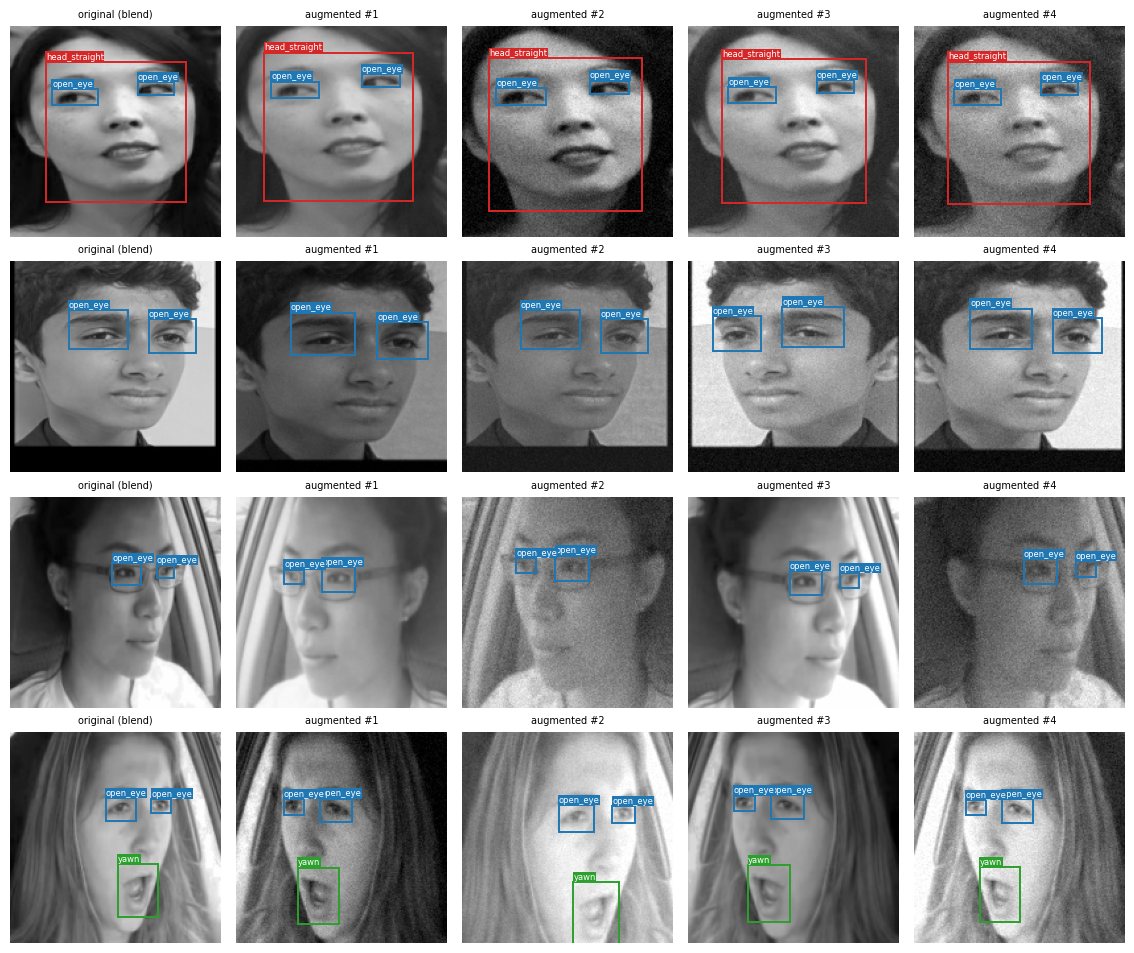

In [ ]:
tf.random.set_seed(SEED)
_tr = splits["train"]
aug_rows = pd.concat([_tr[_tr.kind == kind].sample(min(3, int((_tr.kind == kind).sum())), random_state=SEED)
                      for kind in ("face", "closeup")]).reset_index(drop=True)
eval_rows = closeup_eval_view(aug_rows)
gray_p, ir_p, B_, C_ = pack(aug_rows)
_, _, B_ev, C_ev = pack(eval_rows)
closeup_, _, _ = pack_extra(aug_rows)
_, P_ev, noise_ev = pack_extra(eval_rows)
N_AUG = 4
fig, axes = plt.subplots(len(aug_rows), N_AUG + 2, figsize=(2.3 * (N_AUG + 2), 2.4 * len(aug_rows)), squeeze=False)
for r_i in range(len(aug_rows)):
    for k in range(N_AUG + 2):
        b, c = tf.constant(B_[r_i]), tf.constant(C_[r_i])
        if k == 1:      # the deterministic val/test view
            path = gray_p[r_i] if EVAL_VARIANT == "gray" else ir_p[r_i]
            img = load_pasted(path, tf.constant(P_ev[r_i]), tf.constant(noise_ev[r_i]))
            b, c = B_ev[r_i], C_ev[r_i]
        else:
            a = tf.random.uniform(()) if VARIANT == "mix" else 1.0
            img = a * load_image(gray_p[r_i]) + (1.0 - a) * load_image(ir_p[r_i])
            if k >= 2:
                img, b, c = augment(img, b, c, closeup_[r_i])
        b, c = np.asarray(b), np.asarray(c)
        m = c >= 0
        xyxy = np.c_[b[m, 0] - b[m, 2] / 2, b[m, 1] - b[m, 3] / 2, b[m, 0] + b[m, 2] / 2, b[m, 1] + b[m, 3] / 2]
        rgb = np.repeat(np.clip(np.asarray(img), 0, 1), 3, axis=-1)
        title = (f"{aug_rows.kind[r_i]}: original" if k == 0 else
                 "val/test view" if k == 1 else f"augmented #{k - 1}")
        draw_boxes(axes[r_i, k], rgb, xyxy, c[m], title=title)
plt.tight_layout(); savefig(fig, "aug_preview"); plt.show()

# Part B: The model

First the grid head (target encoding, loss, decoding) and the architecture as code, then the
maths behind each piece, then a layer-by-layer inspection of the built network and a look at
how the dataset meets its grid.

## The grid detector: building blocks, target encoding, loss and decoding

This is the **modern tiny-YOLO head** used by step 2 of notebook 12 and by notebook 14. The
input image is covered by a `G × G` grid at stride 8, so a 160 px input gives a 20 × 20 grid
and each cell is 8 px. For every cell the network outputs `5 + C` numbers:

| channels | meaning | activation / decoding |
|---|---|---|
| `t_obj` | is an object centred near this cell? | `σ(t_obj)` |
| `t_x, t_y` | centre offset | `c_x = (j + 2σ(t_x) − 0.5) / G` (YOLOv5 form: reach ±1 cell) |
| `t_w, t_h` | size, as a fraction of the image | `w = σ(t_w)`, `h = σ(t_h)` (anchor-free) |
| `t_c1..t_cC` | class scores | `σ(t_c)` (independent, multi-label BCE) |

**Assignment.** A ground-truth box is positive in its centre cell **plus the nearest
horizontal and vertical neighbour** (YOLOv5's trick). That gives up to 3 positives per object,
which helps a lot with so few objects per image. When two boxes claim the same cell, the
smaller one wins (an eye is more specific than the head box around it).

**Loss**, normalised by the number of positive cells `N₊`:

$$\mathcal{L} = \lambda_{box}\frac{1}{N_+}\sum_{pos}(1-\mathrm{GIoU}(\hat b,b)) + \lambda_{obj}\frac{1}{N_+}\sum_{all}\mathrm{BCE}(\sigma(t_{obj}),\ \mathbb{1}_{pos}\cdot\mathrm{IoU}(\hat b,b)) + \lambda_{cls}\frac{1}{N_+}\sum_{pos}\sum_c \mathrm{BCE}(\sigma(t_c), y_c)$$

- The objectness target is the predicted box's IoU (YOLOv5), so confidence ranks well-localised
  boxes higher.
- GIoU still gives a gradient when boxes don't overlap.
- The objectness and class biases start at `log(0.01/0.99)` (RetinaNet prior), so the many
  empty cells don't swamp early training.

**Blocks**, kept int8- and CPU-friendly with ReLU6 activations (YOLO uses SiLU):
- `conv_bn`: conv, then batch norm, then ReLU6. Optionally depthwise-separable.
- `c2f_lite`: YOLOv8's C2f in miniature, i.e. a CSP split, a chain of small bottlenecks, then
  concatenating every intermediate.
- `sppf_lite`: three chained 5×5 max-pools, concatenated, which enlarge the receptive field
  cheaply. The head box covers most of the image.
- `decoupled_head`: separate small branches for classification/objectness and for box regression.

**Eye-box filter** (`grid_postprocess(..., eye_filter=True)`, the default). Before NMS, a cell
whose class is an eye is dropped when its box's larger side is over `EYE_MAX_FRAC` = 0.30 of the
image, or its centre y is outside `EYE_CY_RANGE` = 0.15–0.70. On a face crop a real eye is never
that big, nor at the chin or the top edge; the head-sized "eyes" the model learned come from the
full-image eye close-ups. cv-argus applies the very same filter (`PARTS_EYE_MAX_FRAC`,
`PARTS_EYE_CY_RANGE`), so the numbers below are scored the way the Pi decodes. On an
**un-shrunk close-up** the eye label covers the whole image, so the filter removes the matching
prediction and `kind=closeup` eye numbers drop. Notebook 12 scores validation and test with
their close-ups shrunk to face-crop size (`closeup_eval_view`, cell 21), so this only bites on
the as-built splits: cell 48's like-for-like report therefore decodes with `eye_filter=False`,
the way the 2026-10-20 run was scored. A notebook that doesn't shrink close-ups (notebook 14 for
now) should read eye results on `kind=face`.

**Shared verbatim by notebooks 12 / 14** (this cell and the code cell below, eye filter included).

In [ ]:
import keras
from keras import layers

BN_MOMENTUM = 0.97      # YOLOv5 value; Keras default 0.99 lags too far behind fast-moving weights
PRIOR_BIAS = float(np.log(0.01 / 0.99))
GRID_STRIDE = 8
G = IMG // GRID_STRIDE


def conv_bn(x, c, k=3, s=1, dw=False):
    if dw and k > 1:
        x = layers.DepthwiseConv2D(k, s, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=BN_MOMENTUM)(x)
        x = layers.ReLU(6.0)(x)
        x = layers.Conv2D(c, 1, use_bias=False)(x)
    else:
        x = layers.Conv2D(c, k, s, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization(momentum=BN_MOMENTUM)(x)
    return layers.ReLU(6.0)(x)


def c2f_lite(x, c, n=1):
    h = c // 2
    a, b = conv_bn(x, h, 1), conv_bn(x, h, 1)
    outs = [a, b]
    for _ in range(n):
        y = conv_bn(conv_bn(b, h, 3, dw=True), h, 3, dw=True)
        b = layers.Add()([b, y])
        outs.append(b)
    return conv_bn(layers.Concatenate()(outs), c, 1)


def sppf_lite(x, c):
    x = conv_bn(x, c // 2, 1)
    p1 = layers.MaxPooling2D(5, 1, padding="same")(x)
    p2 = layers.MaxPooling2D(5, 1, padding="same")(p1)
    p3 = layers.MaxPooling2D(5, 1, padding="same")(p2)
    return conv_bn(layers.Concatenate()([x, p1, p2, p3]), c, 1)


def decoupled_head(x, c, num_classes=NUM_CLASSES):
    prior = keras.initializers.Constant(PRIOR_BIAS)
    cls_branch = conv_bn(x, c, 3, dw=True)
    obj = layers.Conv2D(1, 1, bias_initializer=prior, name="obj")(cls_branch)
    cls = layers.Conv2D(num_classes, 1, bias_initializer=prior, name="cls")(cls_branch)
    box = layers.Conv2D(4, 1, name="box")(conv_bn(x, c, 3, dw=True))
    return layers.Concatenate(name="grid")([obj, box, cls])     # (G, G, 1 + 4 + C)


class GridEncoder:
    """NumPy target builder for the grid head: (G, G, 5 + C) = [obj, cx, cy, w, h, one-hot]."""

    def __init__(self, grid=G, num_classes=NUM_CLASSES, neighbours=True):
        self.grid, self.nc, self.neighbours = grid, num_classes, neighbours
        self.shape = (grid, grid, 5 + num_classes)

    def __call__(self, boxes, cls):
        t = np.zeros(self.shape, np.float32)
        valid = cls >= 0
        b, c = boxes[valid], cls[valid]
        for k in np.argsort(-(b[:, 2] * b[:, 3])):          # big first, small boxes overwrite
            cx, cy, w, h = b[k]
            gx, gy = cx * self.grid, cy * self.grid
            j, i = min(int(gx), self.grid - 1), min(int(gy), self.grid - 1)
            cells = [(i, j)]
            if self.neighbours:
                fx, fy = gx - j, gy - i
                if fx < 0.5 and j > 0:
                    cells.append((i, j - 1))
                elif fx >= 0.5 and j < self.grid - 1:
                    cells.append((i, j + 1))
                if fy < 0.5 and i > 0:
                    cells.append((i - 1, j))
                elif fy >= 0.5 and i < self.grid - 1:
                    cells.append((i + 1, j))
            for ii, jj in cells:
                t[ii, jj] = 0.0
                t[ii, jj, :5] = (1.0, cx, cy, w, h)
                t[ii, jj, 5 + int(c[k])] = 1.0
        return t


def _grid_xywh_tf(raw):
    g = tf.shape(raw)[1]
    j = tf.cast(tf.range(g), tf.float32)[None, None, :]
    i = tf.cast(tf.range(g), tf.float32)[None, :, None]
    gf = tf.cast(g, tf.float32)
    cx = (j + 2.0 * tf.sigmoid(raw[..., 1]) - 0.5) / gf
    cy = (i + 2.0 * tf.sigmoid(raw[..., 2]) - 0.5) / gf
    return cx, cy, tf.sigmoid(raw[..., 3]), tf.sigmoid(raw[..., 4])


def iou_giou_tf(a, b):
    """a, b: (..., 4) as cx, cy, w, h -> (IoU, GIoU)."""
    ax0, ay0, ax1, ay1 = a[..., 0] - a[..., 2] / 2, a[..., 1] - a[..., 3] / 2, a[..., 0] + a[..., 2] / 2, a[..., 1] + a[..., 3] / 2
    bx0, by0, bx1, by1 = b[..., 0] - b[..., 2] / 2, b[..., 1] - b[..., 3] / 2, b[..., 0] + b[..., 2] / 2, b[..., 1] + b[..., 3] / 2
    inter = tf.nn.relu(tf.minimum(ax1, bx1) - tf.maximum(ax0, bx0)) * tf.nn.relu(tf.minimum(ay1, by1) - tf.maximum(ay0, by0))
    union = a[..., 2] * a[..., 3] + b[..., 2] * b[..., 3] - inter + 1e-9
    iou = inter / union
    hull = (tf.maximum(ax1, bx1) - tf.minimum(ax0, bx0)) * (tf.maximum(ay1, by1) - tf.minimum(ay0, by0)) + 1e-9
    return iou, iou - (hull - union) / hull


def grid_loss(lam_box=5.0, lam_obj=1.0, lam_cls=1.0):
    def loss(y_true, y_pred):
        pos = y_true[..., 0]
        npos = tf.maximum(tf.reduce_sum(pos), 1.0)
        pred = tf.stack(_grid_xywh_tf(y_pred), -1)
        iou, giou = iou_giou_tf(pred, y_true[..., 1:5])
        box = tf.reduce_sum((1.0 - giou) * pos) / npos
        obj_t = pos * tf.stop_gradient(tf.clip_by_value(iou, 0.0, 1.0))
        obj = tf.reduce_sum(tf.nn.sigmoid_cross_entropy_with_logits(labels=obj_t, logits=y_pred[..., 0])) / npos
        cls = tf.reduce_sum(tf.reduce_sum(tf.nn.sigmoid_cross_entropy_with_logits(
            labels=y_true[..., 5:], logits=y_pred[..., 5:]), -1) * pos) / npos
        return lam_box * box + lam_obj * obj + lam_cls * cls
    return loss


def _sig(x):
    return 1.0 / (1.0 + np.exp(-x))


# Eye-box sanity filter, the same one cv-argus deploys (src/cv-argus/src/constants.py
# PARTS_EYE_MAX_FRAC / PARTS_EYE_CY_RANGE, model/parts_detector.py implausible_eye_mask).
EYE_MAX_FRAC = 0.30           # an eye's larger side, as a fraction of the crop side
EYE_CY_RANGE = (0.15, 0.70)   # an eye's centre y, crop-normalised (0 = top)


def implausible_eye_mask(cls, cy, w, h, max_frac=EYE_MAX_FRAC, cy_range=EYE_CY_RANGE):
    """True where the class is an eye class and the box can't be a real eye on a face crop."""
    eye = np.isin(cls, EYE_CLASSES)
    bad = np.zeros(np.shape(cls), bool)
    if max_frac is not None:
        bad |= np.maximum(w, h) > max_frac
    if cy_range is not None:
        bad |= (cy < cy_range[0]) | (cy > cy_range[1])
    return eye & bad


def grid_postprocess(raw, conf_floor=0.001, pre_nms=200, eye_filter=True):
    """One image's raw grid (G, G, 5 + C) -> (xyxy boxes, scores, classes) after NMS. With
    `eye_filter`, implausible eye cells are dropped before NMS, exactly as deployed."""
    g = raw.shape[0]
    j, i = np.meshgrid(np.arange(g), np.arange(g))
    cx = (j + 2 * _sig(raw[..., 1]) - 0.5) / g
    cy = (i + 2 * _sig(raw[..., 2]) - 0.5) / g
    w, h = _sig(raw[..., 3]), _sig(raw[..., 4])
    cls_p = _sig(raw[..., 5:])
    cls = cls_p.argmax(-1)
    score = _sig(raw[..., 0]) * cls_p.max(-1)
    m = score > conf_floor
    if eye_filter:
        m &= ~implausible_eye_mask(cls, cy, w, h)
    order = np.argsort(-score[m])[:pre_nms]
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)[m][order].clip(0, 1)
    return nms_per_class(boxes, score[m][order], cls[m][order])

## The architecture: `tiny_yolo_w1`

A YOLOv5/YOLOv8-style detector scaled down to about 46k parameters:

    160×160×1 ─ stem conv s2 ─ dw-conv s2 ─ C2f-lite ─ dw-conv s2 ─ C2f-lite×2 ─ SPPF-lite ─ decoupled head
       160         80            40          40          20            20            20        20×20×(5+C)

- **Stride 8 → a 20 × 20 grid.** Eyes are only about 25 px, so a coarser 16 px cell (the old
  YOLOv1 baseline) was too coarse for them.
- **Neighbour-cell assignment** gives up to 3 positive cells per object.
- **IoU-aware objectness, GIoU box loss, sigmoid multi-label classes** (see the maths below).
- `width` scales every channel count and is the main size knob; `w1` means `width = 1.0`.

`build_tiny_yolo` and the head's layer names are what `src/cv-argus` loads, so don't rename them.

In [ ]:
def build_tiny_yolo(width=1.0, name=None):
    c = lambda n: max(8, int(round(n * width / 8)) * 8)
    inp = keras.Input((IMG, IMG, 1))
    x = conv_bn(inp, c(16), 3, 2)              # 80
    x = conv_bn(x, c(32), 3, 2, dw=True)       # 40
    x = c2f_lite(x, c(32), 1)
    x = conv_bn(x, c(64), 3, 2, dw=True)       # 20 (stride 8)
    x = c2f_lite(x, c(64), 2)
    x = sppf_lite(x, c(64))
    out = decoupled_head(x, c(48))
    return keras.Model(inp, out, name=name or f"tiny_yolo_w{width:g}")

## The maths behind the model

This section derives every block above, in the order data flows through the network. Notation:
an input feature map $X \in \mathbb{R}^{H \times W \times C_{in}}$, a kernel of side $k$, a stride
$s$, and $C_{out}$ output channels.

### 1. Convolution

A 2-D convolution layer slides $C_{out}$ learnable kernels $K^{(o)} \in \mathbb{R}^{k\times k\times C_{in}}$
over the input. Each output value is a weighted sum of a $k \times k$ neighbourhood across
**all** input channels, plus a bias:

$$Y_{i,j,o} = b_o + \sum_{u=0}^{k-1}\sum_{v=0}^{k-1}\sum_{c=1}^{C_{in}} K^{(o)}_{u,v,c}\; X_{s\,i+u-p,\ s\,j+v-p,\ c}$$

(deep-learning "convolution" is technically cross-correlation; the kernel isn't flipped).
Two properties make it the right tool for images:
- **Weight sharing:** the same kernel is used at every position, so an "eye-edge detector"
  learned in one place works everywhere (translation equivariance).
- **Locality:** each output depends only on a small window, so the parameter count doesn't grow
  with the image size.

With padding $p$ (`"same"` keeps $H_{out} = \lceil H/s \rceil$), the output size and cost are

$$H_{out} = \left\lfloor \frac{H + 2p - k}{s} \right\rfloor + 1, \qquad
\#\text{params} = k^2\, C_{in}\, C_{out} + C_{out}, \qquad
\text{MACs} = k^2\, C_{in}\, C_{out}\, H_{out} W_{out}.$$

**Stride 2** halves the resolution. The network uses three of them: $160 \to 80 \to 40 \to 20$.

### 2. Depthwise-separable convolution (`dw=True`)

A standard conv mixes space and channels at once. A depthwise-separable conv (MobileNet) splits
the work in two:
1. a **depthwise** $k\times k$ conv that filters each channel on its own (its own kernel per
   channel);
2. a **pointwise** $1\times 1$ conv that mixes channels.

$$\text{cost}_{dw\text{-}sep} = k^2 C_{in} H W + C_{in} C_{out} H W
\quad\Rightarrow\quad \frac{\text{cost}_{dw\text{-}sep}}{\text{cost}_{std}} = \frac{1}{C_{out}} + \frac{1}{k^2}$$

With $k = 3$ and $C_{out} = 64$ that's about **0.13×** the multiply-adds. This is the main
reason the whole detector fits in about 46k parameters and well under a millisecond on the Pi.

### 3. Batch normalisation and ReLU6 (`conv_bn`)

Every conv is followed by BatchNorm, which standardises each channel over the mini-batch
$\mathcal{B}$ and then re-scales it with learned $\gamma, \beta$:

$$\hat x = \frac{x - \mu_\mathcal{B}}{\sqrt{\sigma^2_\mathcal{B} + \epsilon}}, \qquad y = \gamma \hat x + \beta .$$

At inference there is no batch, so BatchNorm uses running averages updated during training:
$\mu \leftarrow m\,\mu + (1-m)\,\mu_\mathcal{B}$, with momentum $m = 0.97$ (`BN_MOMENTUM`). If the
weights are still moving when training stops, those averages lag behind them, and eval-mode
outputs drift. That's why `recalibrate_bn` re-estimates them for the final weights; in this
project it once took eval mAP from 0.00 to 0.99. At export, BN folds into the conv
($W' = \gamma W / \sigma$, $b' = \beta - \gamma\mu/\sigma$), so it costs nothing on the Pi.

The activation is **ReLU6**, $\;\mathrm{ReLU6}(x) = \min(\max(0, x), 6)$. It is piecewise linear
like ReLU, and bounded, so activations have a known range $[0, 6]$ that int8 quantisation can
represent precisely. YOLO's SiLU ($x\,\sigma(x)$) is smoother but unbounded and costlier on a CPU.

### 4. Receptive field, residuals, C2f-lite and SPPF-lite

**Receptive field.** The input region that can influence one output cell grows layer by layer.
With $r$ the receptive field and $j$ the cumulative stride ("jump"), each layer with kernel $k$
and stride $s$ updates them as

$$r_{l} = r_{l-1} + (k_l - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l, \qquad r_0 = j_0 = 1 .$$

The final cells have $j = 8$, so the grid is $160/8 = 20$ cells per side. Their receptive field
must cover the largest object, the head box at about 100–150 px. The inspection cell below
computes it from the actual layers.

**Residual connection** (inside C2f-lite): $\;y = x + F(x)$. The block learns a *correction*
$F$ rather than a whole new mapping. Gradients flow straight through the identity path,
$\partial y / \partial x = I + \partial F/\partial x$, which keeps a deep stack trainable.

**C2f-lite** (YOLOv8's C2f, CSP-style). The block works in three steps:
1. two $1\times1$ convs split the input into halves $a$ and $b$;
2. $b$ goes through $n$ residual bottlenecks, $b_t = b_{t-1} + F_t(b_{t-1})$;
3. **every** intermediate $[a, b_0, b_1, \dots, b_n]$ is concatenated and fused by a $1\times1$
   conv.

Concatenating all depths gives the head features with several receptive fields at once, at half
the cost of running the full width through every bottleneck.

**SPPF-lite.** It chains three $5\times5$ stride-1 max-pools and concatenates their outputs.
Because $\max$ over a $5\times5$ window of a $5\times5$ max equals a $9\times9$ max:

$$P_1 = \max_{5\times5} X,\quad P_2 = \max_{5\times5} P_1 = \max_{9\times9} X,\quad P_3 = \max_{13\times13} X ,$$

so $[X, P_1, P_2, P_3]$ pools at 1, 5, 9 and 13 cells (8, 40, 72, 104 px). That gives the
head-box classifier a near-global view, with no extra weights.

### 5. The grid head: decoding, assignment and the loss

**Decoding.** For grid cell $(i, j)$ the head emits raw values
$t = (t_{obj}, t_x, t_y, t_w, t_h, t_{c_1..c_C})$, decoded with the logistic sigmoid
$\sigma(z) = 1/(1+e^{-z})$:

$$c_x = \frac{j + 2\sigma(t_x) - 0.5}{G},\quad c_y = \frac{i + 2\sigma(t_y) - 0.5}{G},\quad
w = \sigma(t_w),\quad h = \sigma(t_h),\quad \text{score}_c = \sigma(t_{obj})\,\sigma(t_{c}) .$$

- $2\sigma(\cdot) - 0.5 \in (-0.5, 1.5)$ lets a cell place a centre up to half a cell outside
  itself. That is what makes neighbour assignment work.
- **Anchor-free:** $w, h$ are fractions of the image directly, with no anchor box priors to tune.
- Classes use independent sigmoids rather than a softmax (multi-label). The reported class is
  $\arg\max_c$ and the score is $\sigma(t_{obj})\max_c\sigma(t_c)$.

**Assignment (`GridEncoder`).** A ground-truth box is positive in the cell holding its centre,
**plus** the nearest horizontal and the nearest vertical neighbour, so up to 3 positives per
object. Boxes are written largest-first, so when two boxes claim a cell the **smaller** wins (an
eye beats the head box around it). The "dataset meets the grid" cell below counts how often
that happens.

**Box loss: IoU and GIoU.** For predicted box $\hat B$ and ground truth $B$:

$$\mathrm{IoU} = \frac{|\hat B \cap B|}{|\hat B \cup B|}, \qquad
\mathrm{GIoU} = \mathrm{IoU} - \frac{|C \setminus (\hat B \cup B)|}{|C|},$$

where $C$ is the smallest box enclosing both. IoU is 0 for any two non-overlapping boxes, so
it has no gradient there. GIoU keeps pulling them together, and is in $[-1, 1]$.

**Binary cross-entropy** for a probability $p = \sigma(t)$ and a target $y \in [0, 1]$:
$\;\mathrm{BCE}(p, y) = -[\,y\log p + (1-y)\log(1-p)\,]$.

**The full loss**, normalised by the number of positive cells $N_+$, with
$\lambda_{box} = 5,\ \lambda_{obj} = \lambda_{cls} = 1$:

$$\mathcal{L} = \frac{\lambda_{box}}{N_+}\sum_{\text{pos}}\big(1-\mathrm{GIoU}(\hat B, B)\big)
+ \frac{\lambda_{obj}}{N_+}\sum_{\text{all cells}}\mathrm{BCE}\big(\sigma(t_{obj}),\ \mathbb{1}_{pos}\cdot\mathrm{IoU}(\hat B, B)\big)
+ \frac{\lambda_{cls}}{N_+}\sum_{\text{pos}}\sum_{c}\mathrm{BCE}\big(\sigma(t_c), y_c\big)$$

- **IoU-aware objectness.** The objectness target at a positive cell is the predicted box's IoU
  (gradient stopped), not 1. Confidence therefore ranks well-localised boxes higher, which is
  exactly what NMS and mAP reward.
- **Prior bias.** Most of the $20\times20 = 400$ cells are empty. If objectness started at
  $\sigma(0) = 0.5$, the empty cells' BCE would dominate the first updates. Setting the initial
  bias to $b = \log\frac{\pi}{1-\pi}$ makes $\sigma(b) = \pi$; with $\pi = 0.01$,
  $b = \log(0.01/0.99) \approx -4.6$ (the RetinaNet prior). The grid cell below measures the
  real positive-cell fraction to check that $\pi = 0.01$ is the right order of magnitude.

### 6. From raw grid to detections, and how they're scored

**Non-maximum suppression.** Neighbour assignment means several cells fire for one object.
Per class:
1. sort the boxes by score;
2. keep the best one;
3. drop every remaining box with IoU ≥ 0.5 against it;
4. repeat with the next box still left.

**Precision, recall, AP.** At a score threshold, a prediction is a true positive (TP) if it
matches an unused ground-truth box of its class with IoU ≥ 0.5:

$$P = \frac{TP}{TP + FP}, \qquad R = \frac{TP}{TP + FN} .$$

Sweeping the threshold traces a precision–recall curve. **AP** is the area under its monotone
envelope, sampled at 101 recall points (COCO style). **mAP** averages AP over classes, and
**mAP@0.5:0.95** also averages over IoU thresholds 0.50, 0.55, …, 0.95:

$$\mathrm{AP} = \frac{1}{101}\sum_{r \in \{0, 0.01, \dots, 1\}} \max_{r' \ge r} P(r') .$$

### 7. Optimisation: AdamW with cosine decay

AdamW keeps running averages of the gradient $g_t$ and of its square, and applies weight decay
directly to the weights rather than through the loss:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t,\quad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2,\quad
\theta_t = \theta_{t-1} - \eta_t\Big(\frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon} + \lambda\,\theta_{t-1}\Big)$$

with bias-corrected $\hat m_t, \hat v_t$ and weight decay $\lambda = 5\cdot10^{-4}$. The learning
rate follows a cosine from $\eta_0 = 2\cdot10^{-3}$ down to $\alpha\,\eta_0$ ($\alpha = 0.05$) over
all $T$ training steps:

$$\eta_t = \eta_0\Big[\alpha + (1-\alpha)\,\tfrac12\big(1 + \cos(\pi t / T)\big)\Big] .$$

### 8. int8 quantisation (what the Pi runs)

Full-integer quantisation maps each real tensor to 8-bit integers with an affine map:

$$q = \mathrm{clamp}\Big(\mathrm{round}\big(\tfrac{x}{s}\big) + z,\ -128,\ 127\Big), \qquad x \approx s\,(q - z) .$$

- Weights get a scale per output channel.
- Activation scales $s$ and zero-points $z$ are calibrated by running 200 training images
  through the float model.
- Convs then run as int8 × int8 → int32 accumulations. That gives about 4× smaller weights and
  the fast XNNPACK path on the Pi's ARM cores.

The bounded ReLU6 range keeps the rounding error small. Part D shows the accuracy cost (float vs
int8).

### A note on recurrence: there is none in this model

This detector is **purely convolutional and feed-forward**. Each frame is processed on its own,
$\hat y_t = f_\theta(x_t)$, with no state carried between frames. A recurrent network would add a
hidden state, $h_t = g(h_{t-1}, x_t)$, so its output could depend on the past.

In Argus, time is handled **after** the detector: cv-argus runs an IoU tracker and timed rules
(eyes closed for longer than T seconds, head down for longer than T…) over the per-frame
detections. A learned temporal model, e.g. an LSTM over the per-frame detection vector at 5 fps,
is possible future work on top of this detector. It would not change the detector itself.

### Resources to go deeper

**Convolutions and CNNs**
- Stanford CS231n, *Convolutional Neural Networks* notes: https://cs231n.github.io/convolutional-networks/
- Goodfellow, Bengio & Courville, *Deep Learning*, ch. 9 "Convolutional Networks": https://www.deeplearningbook.org/contents/convnets.html
- Zhang et al., *Dive into Deep Learning*, ch. 7 (CNNs, with runnable code): https://d2l.ai/chapter_convolutional-neural-networks/index.html
- Dumoulin & Visin (2016), *A guide to convolution arithmetic for deep learning*: https://arxiv.org/abs/1603.07285
- Howard et al. (2017), *MobileNets* (depthwise-separable convolutions): https://arxiv.org/abs/1704.04861
- Ioffe & Szegedy (2015), *Batch Normalization*: https://arxiv.org/abs/1502.03167
- He et al. (2016), *Deep Residual Learning* (residual connections): https://arxiv.org/abs/1512.03385

**Object detection and the YOLO family**
- Redmon et al. (2016), *You Only Look Once* (YOLOv1, the grid idea): https://arxiv.org/abs/1506.02640
- Redmon & Farhadi (2018), *YOLOv3*: https://arxiv.org/abs/1804.02767
- Ultralytics YOLOv5 / YOLOv8 documentation (neighbour assignment, C2f, SPPF, decoupled head): https://docs.ultralytics.com/
- Wang et al. (2019), *CSPNet* (the cross-stage-partial split behind C2f): https://arxiv.org/abs/1911.11929
- He et al. (2014), *Spatial Pyramid Pooling* (the idea behind SPPF): https://arxiv.org/abs/1406.4729
- Rezatofighi et al. (2019), *Generalized IoU*: https://arxiv.org/abs/1902.09630
- Lin et al. (2017), *Focal Loss / RetinaNet* (the prior-bias initialisation): https://arxiv.org/abs/1708.02002

**Training and deployment**
- Loshchilov & Hutter (2019), *Decoupled Weight Decay Regularization* (AdamW): https://arxiv.org/abs/1711.05101
- Loshchilov & Hutter (2017), *SGDR* (cosine learning-rate schedules): https://arxiv.org/abs/1608.03983
- Jacob et al. (2018), *Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference*: https://arxiv.org/abs/1712.05877
- TensorFlow Lite post-training integer quantisation guide: https://ai.google.dev/edge/litert/models/post_training_integer_quant

### Inspecting the built network

The table below is built from the real Keras layers. For every conv / pooling layer it shows
the output shape, the parameters, the cumulative stride $j$ and the receptive field $r$ (from the
recursion in §4; a merge takes the largest $r$ of its inputs). Then come the parameters per
stage, and the float vs int8 size.

             layer            type        output  params  stride j  receptive field r (px)
            conv2d          Conv2D  (80, 80, 16)     144         2                       3
  depthwise_conv2d DepthwiseConv2D  (40, 40, 16)     144         4                       7
          conv2d_1          Conv2D  (40, 40, 32)     512         4                       7
          conv2d_3          Conv2D  (40, 40, 16)     512         4                       7
depthwise_conv2d_1 DepthwiseConv2D  (40, 40, 16)     144         4                      15
          conv2d_4          Conv2D  (40, 40, 16)     256         4                      15
depthwise_conv2d_2 DepthwiseConv2D  (40, 40, 16)     144         4                      23
          conv2d_5          Conv2D  (40, 40, 16)     256         4                      23
          conv2d_2          Conv2D  (40, 40, 16)     512         4                       7
               add             Add  (40, 40, 16)       0         4                      23

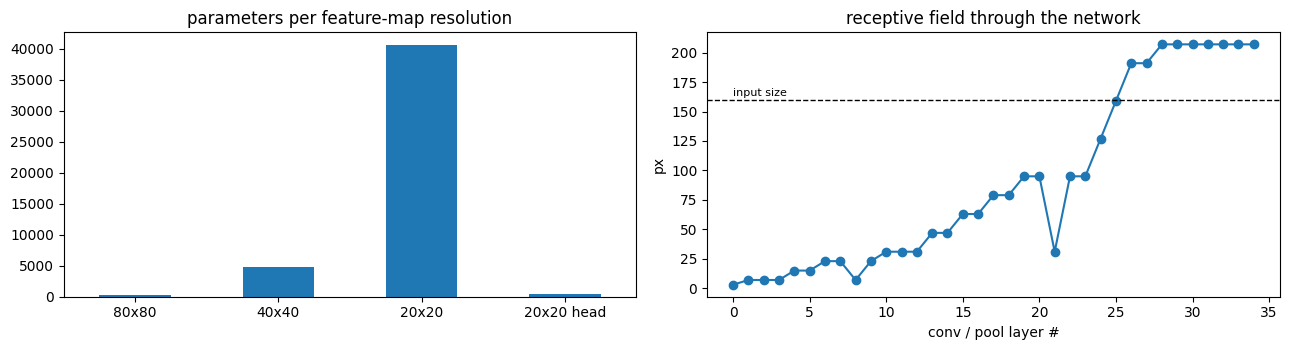

In [ ]:
def receptive_fields(model):
    info = {}
    for L in model.layers:
        if isinstance(L, keras.layers.InputLayer):
            info[L.name] = (1, 1)
            continue
        ins = L.input if isinstance(L.input, (list, tuple)) else [L.input]
        parents = [info[t._keras_history.operation.name] for t in ins]
        r, j = max(p[0] for p in parents), parents[0][1]
        if isinstance(L, (layers.Conv2D, layers.DepthwiseConv2D, layers.MaxPooling2D)):
            k = L.pool_size[0] if isinstance(L, layers.MaxPooling2D) else L.kernel_size[0]
            r, j = r + (k - 1) * j, j * L.strides[0]
        info[L.name] = (r, j)
    return info


_m = build_tiny_yolo(1.0)
rf = receptive_fields(_m)
rows = []
for L in _m.layers:
    if isinstance(L, (layers.Conv2D, layers.DepthwiseConv2D, layers.MaxPooling2D, layers.Concatenate, layers.Add)):
        r, j = rf[L.name]
        rows.append({"layer": L.name, "type": type(L).__name__, "output": str(tuple(L.output.shape[1:])),
                     "params": L.count_params(), "stride j": j, "receptive field r (px)": r})
layer_table = pd.DataFrame(rows)
pd.set_option("display.max_rows", 200)
print(layer_table.to_string(index=False))
print(f"\n{_m.name}: {_m.count_params():,} parameters "
      f"(~{_m.count_params() * 4 / 1024:.0f} KB float32, ~{_m.count_params() / 1024:.0f} KB int8 weights); "
      f"output grid {tuple(_m.output.shape[1:])}; final receptive field {rf[_m.layers[-1].name][0]} px "
      f"on a {IMG} px input")

stage = {}
for L in _m.layers:
    if L.count_params():
        res = L.output.shape[1]
        key = f"{res}x{res}" + (" head" if L.name in ("obj", "cls", "box") else "")
        stage[key] = stage.get(key, 0) + L.count_params()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
pd.Series(stage).plot.bar(ax=axes[0], rot=0, title="parameters per feature-map resolution")
conv_rows = layer_table[layer_table.type.isin(["Conv2D", "DepthwiseConv2D", "MaxPooling2D"])]
axes[1].plot(range(len(conv_rows)), conv_rows["receptive field r (px)"], marker="o")
axes[1].axhline(IMG, ls="--", c="k", lw=1); axes[1].text(0, IMG + 3, "input size", fontsize=8)
axes[1].set(title="receptive field through the network", xlabel="conv / pool layer #", ylabel="px")
plt.tight_layout(); savefig(fig, "b_model_inspection"); plt.show()

### How the dataset meets the grid

The real `GridEncoder` runs over every training image's boxes, to measure what the loss
actually sees:
- **Positives per image and positive-cell fraction.** That fraction is the real class prior of
  objectness. Compare it with the $\pi = 0.01$ behind the prior bias.
- **Centre-cell collisions per class.** Because the smaller box wins a shared cell, a big box
  (the head) can lose its centre cell to an eye. "Lost centre" means the box's own centre cell
  now belongs to another box. "Fully lost" means none of its up-to-3 cells survived, so that
  object is never trained on.
- **Eye size in cells:** how many 8 px cells an eye box spans.

grid 20x20 = 400 cells; positives per image: mean 5.2, median 3, max 14
positive-cell fraction = 0.0129  (prior pi = 0.01 -> bias -4.60)

Centre-cell collisions in the training targets:
               boxes  lost centre  fully lost  lost centre %  fully lost %
open_eye       25750           17           1           0.07          0.00
closed_eye     14124            1           0           0.01          0.00
yawn            1587            6           3           0.38          0.19
head_straight   5521            3           0           0.05          0.00
head_down        633            3           1           0.47          0.16
-> /content/drive/MyDrive/Argus/models/parts_det/figures/b_grid_assignment_20261020_2335.png


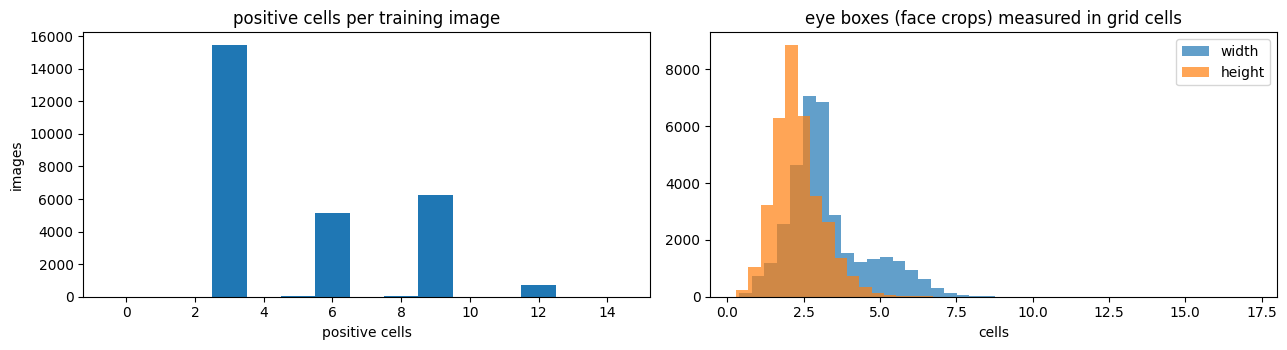

In [ ]:
enc = GridEncoder()
stats = {c: {"boxes": 0, "lost centre": 0, "fully lost": 0} for c in CLASSES}
pos_per_img = []
for cl, bx in zip(splits["train"].classes, splits["train"].boxes):
    if len(cl) == 0:
        continue
    t = enc(bx.astype(np.float32), cl.astype(np.int32))
    pos_per_img.append(t[..., 0].sum())
    for c, b in zip(cl, bx):
        name = CLASSES[c]
        stats[name]["boxes"] += 1
        mine = (t[..., 0] == 1) & np.isclose(t[..., 1], b[0]) & np.isclose(t[..., 2], b[1]) & (t[..., 5 + c] == 1)
        j, i = min(int(b[0] * G), G - 1), min(int(b[1] * G), G - 1)
        stats[name]["lost centre"] += int(not mine[i, j])
        stats[name]["fully lost"] += int(not mine.any())
coll = pd.DataFrame(stats).T
coll["lost centre %"] = (100 * coll["lost centre"] / coll.boxes.clip(lower=1)).round(2)
coll["fully lost %"] = (100 * coll["fully lost"] / coll.boxes.clip(lower=1)).round(2)
pos_per_img = np.array(pos_per_img)
print(f"grid {G}x{G} = {G * G} cells; positives per image: mean {pos_per_img.mean():.1f}, "
      f"median {np.median(pos_per_img):.0f}, max {pos_per_img.max():.0f}")
print(f"positive-cell fraction = {pos_per_img.mean() / (G * G):.4f}  (prior pi = 0.01 -> bias {PRIOR_BIAS:.2f})\n")
print("Centre-cell collisions in the training targets:")
print(coll.to_string())

eye = geo[geo["class"].isin(["open_eye", "closed_eye"]) & (geo.kind == "face")]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(pos_per_img, bins=np.arange(0, pos_per_img.max() + 2) - 0.5)
axes[0].set(title="positive cells per training image", xlabel="positive cells", ylabel="images")
axes[1].hist(eye.w_px / CELL_PX, bins=40, alpha=0.7, label="width"); axes[1].hist(eye.h_px / CELL_PX, bins=40, alpha=0.7, label="height")
axes[1].set(title="eye boxes (face crops) measured in grid cells", xlabel="cells"); axes[1].legend()
plt.tight_layout(); savefig(fig, "b_grid_assignment"); plt.show()

# Part C: Training `tiny_yolo_w1`

### Training setup

Everything that decides how the model trains, in one place. `TRAIN` holds the values passed to
the calls below. The rows marked *(fixed)* are set inside the shared `train_detector` /
`grid_loss` / model cells (shared with notebook 14), so they're listed, not re-implemented.

| what | value |
|---|---|
| model | `tiny_yolo_w1` (`build_tiny_yolo(width=1.0)`), ~46k params |
| input | `IMG × IMG × 1` gray, 0–1; train `VARIANT` (default `mix`: random gray/IR blend), eval `EVAL_VARIANT` (`ir`) |
| output | `G × G × (5 + C)` grid, stride 8 (20 × 20 at 160 px) |
| loss | `5 · (1 − GIoU)` on positive cells + `1 · BCE(objectness, IoU)` on all cells + `1 · BCE(classes)` on positives, each ÷ `N₊` |
| assignment | centre cell + nearest horizontal + nearest vertical neighbour; the smaller box wins a shared cell |
| optimiser | AdamW, weight decay 5e-4 *(fixed)* |
| learning rate | 2e-3, cosine decay to 5% of it over all steps *(fixed shape)* |
| batch / epochs | 64 / up to 150 |
| early stopping | on validation mAP@0.5, computed every 5 epochs (on ≤ 1,500 valid images), stop after 6 checks without improvement; the **best** weights are kept |
| after training | BatchNorm statistics re-estimated for the final weights (`recalibrate_bn`) |
| BatchNorm | momentum 0.97 *(fixed)* |
| augmentation | close-ups always shrunk onto a mean-gray + noise background (eye 8–24 %, mouth 15–35 % of the side, placed where that part sits on a face crop); face crops zoomed out with p = 0.3 to 60–95 % of the side; horizontal flip; 80–100% zoom/translate crop (boxes clipped, those whose centre leaves are dropped); brightness ±0.15, contrast 0.7–1.3, gamma 0.7–1.4, Gaussian sensor noise σ ≤ 0.04 |
| label cleaning | training only: eye labels on face crops with a side over 0.30 of the image are dropped (`EYE_LABEL_MAX_FRAC`, = cv-argus `PARTS_EYE_MAX_FRAC`) |
| validation / test images | close-ups shrunk the same way, deterministically (seeded per image id, `closeup_eval_view`); face crops as built |
| decoding for every score | `grid_postprocess` with the deployed eye-box filter (`eye_filter=True`); cell 48 also prints a like-for-like report (as-built test, `eye_filter=False`) against the 2026-10-20 run |
| export | int8 TFLite, full-integer, calibrated on 200 training images |

### Training, prediction and int8 export (shared by every Keras detector here)

- `ValMAP` computes the validation mAP@0.5 every few epochs and exposes it as `val_map50` for
  early stopping and best-weight selection. Loss alone is a poor proxy for detection quality.
- `export_tflite_int8` does full-integer quantisation calibrated on 200 training images. Input
  and output stay float32, and everything inside is int8. That's what the Pi runs, through
  XNNPACK.

In [ ]:
class ValMAP(keras.callbacks.Callback):
    def __init__(self, df, decode, every=5, max_images=1500):
        super().__init__()
        self.df = df.sample(min(len(df), max_images), random_state=SEED) if len(df) > max_images else df
        self.decode, self.every, self.best, self.last, self.best_weights = decode, every, -1.0, 0.0, None

    def on_epoch_end(self, epoch, logs=None):
        if epoch % self.every == 0 or epoch == self.params["epochs"] - 1:
            preds = predict_keras(self.model, self.df, self.decode)
            gts = gts_for(self.df)
            self.last = float(np.nanmean([average_precision(preds, gts, c, [0.5])[0] for c in range(NUM_CLASSES)]))
            if self.last > self.best:
                self.best, self.best_weights = self.last, self.model.get_weights()
            print(f"  val mAP50 = {self.last:.4f} (best {self.best:.4f})")
        logs["val_map50"] = self.last


def train_detector(model, loss, encoder, decode, epochs, lr=2e-3, batch=64, patience=6, every=5):
    epochs = 2 if SMOKE else epochs
    train_ds = make_dataset(splits["train"], encoder, training=True, batch=batch)
    steps = max(1, int(np.ceil(len(splits["train"]) / batch)))
    sched = keras.optimizers.schedules.CosineDecay(lr, decay_steps=epochs * steps, alpha=0.05)
    model.compile(optimizer=keras.optimizers.AdamW(sched, weight_decay=5e-4), loss=loss)
    vm = ValMAP(splits["valid"], decode, every=1 if SMOKE else every)
    stop = keras.callbacks.EarlyStopping(monitor="val_map50", mode="max", patience=patience * every,
                                         restore_best_weights=False)
    hist = model.fit(train_ds, epochs=epochs, callbacks=[vm, stop], verbose=2)
    if vm.best_weights is not None:
        model.set_weights(vm.best_weights)
    recalibrate_bn(model, encoder)
    return hist, vm.best


def recalibrate_bn(model, encoder, n_batches=100, batch=64):
    """Refresh BatchNorm running statistics for the FINAL weights: forward passes in training
    mode over clean (un-augmented) train images, with weights untouched. Close-ups are shrunk
    deterministically (`closeup_eval_view`), the way validation and test see them. Without this, the
    running averages lag behind weights that were still moving, and eval-mode outputs drift. A
    memorisation test showed that this alone took eval mAP@0.5 from 0.00 to 0.99 for the same
    weights."""
    ds = make_dataset(closeup_eval_view(splits["train"]), encoder, training=False, batch=batch).take(2 if SMOKE else n_batches)
    for x, _ in ds:
        model(x, training=True)


def predict_keras(model, df, decode, variant=None, batch=128):
    raw = model.predict(image_dataset(df, variant, batch), verbose=0)
    return {iid: decode(r) for iid, r in zip(df.image_id, raw)}


def export_tflite_int8(model, path, n_calib=200):
    sm_dir = f"{WORK_DIR}/saved_model_{model.name}"
    if hasattr(model, "export"):
        model.export(sm_dir, verbose=False)
    else:
        tf.saved_model.save(model, sm_dir)
    conv = tf.lite.TFLiteConverter.from_saved_model(sm_dir)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    # Calibration images as the model is scored: close-ups shrunk (closeup_eval_view).
    calib = closeup_eval_view(splits["train"].sample(min(n_calib, len(splits["train"])), random_state=SEED))
    imgs = [x.numpy() for x in image_dataset(calib, batch=1)]
    conv.representative_dataset = lambda: ([x] for x in imgs)
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    with open(path, "wb") as f:
        f.write(conv.convert())
    print(f"-> {path} ({os.path.getsize(path) / 1024:.1f} KB)")
    return path


def predict_tflite(path, df, decode, variant=None):
    it = tf.lite.Interpreter(model_path=str(path), num_threads=4)
    it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    preds = {}
    for iid, x in zip(df.image_id, image_dataset(df, variant, batch=1)):
        it.set_tensor(inp["index"], x.numpy().astype(np.float32)); it.invoke()
        preds[iid] = decode(it.get_tensor(out["index"])[0])
    return preds

In [ ]:
TRAIN = {
    "width": 1.0,           # channel multiplier -> model name tiny_yolo_w1
    "epochs": 150,          # upper bound; early stopping usually ends sooner
    "lr": 2e-3,             # AdamW peak LR (cosine decay to 5% inside train_detector)
    "batch": 64,
    "eval_every": 5,        # epochs between validation mAP@0.5 checks
    "patience": 6,          # validation checks without improvement before stopping
    "lam_box": 5.0, "lam_obj": 1.0, "lam_cls": 1.0,   # grid_loss weights
}
setup = {**TRAIN, "IMG": IMG, "grid": f"{G}x{G} (stride {GRID_STRIDE})", "classes": CLASSES,
         "train images": len(splits["train"]), "valid images": len(splits["valid"]),
         "VARIANT": VARIANT, "EVAL_VARIANT": EVAL_VARIANT, "BN_MOMENTUM": BN_MOMENTUM,
         "weight_decay (fixed)": 5e-4, "cosine alpha (fixed)": 0.05, "SMOKE": SMOKE}
print(pd.Series(setup, dtype=object).to_string())

width                                                                 1.0
epochs                                                                150
lr                                                                  0.002
batch                                                                  64
eval_every                                                              5
patience                                                                6
lam_box                                                               5.0
lam_obj                                                               1.0
lam_cls                                                               1.0
IMG                                                                   160
grid                                                     20x20 (stride 8)
classes                 [open_eye, closed_eye, yawn, head_straight, he...
train images                                                        27656
valid images                          

### Sanity check, then the training run

A sanity check first: **overfit one batch.** If the loss can't be driven close to zero on 16
images, the encoding, loss or decoding is wrong, and there's no point spending GPU time on the
full run. Then `tiny_yolo_w1` trains with `TRAIN`, and is scored on the validation set.

In [ ]:
def overfit_check(model, loss, encoder, steps=150):
    batch = next(iter(make_dataset(splits["train"].head(16), encoder, training=False, batch=16)))
    model.compile(optimizer=keras.optimizers.Adam(3e-3), loss=loss)
    first = float(model.train_on_batch(*batch))
    for _ in range(30 if SMOKE else steps):
        last = float(model.train_on_batch(*batch))
    print(f"overfit one batch: loss {first:.3f} -> {last:.3f}")
    return first, last

In [19]:
overfit_check(build_tiny_yolo(TRAIN["width"]), grid_loss(TRAIN["lam_box"], TRAIN["lam_obj"], TRAIN["lam_cls"]), GridEncoder())

model = build_tiny_yolo(TRAIN["width"])
print(f"{model.name}: {model.count_params():,} params")
hist, best_val_map50 = train_detector(
    model, grid_loss(TRAIN["lam_box"], TRAIN["lam_obj"], TRAIN["lam_cls"]), GridEncoder(), grid_postprocess,
    epochs=TRAIN["epochs"], lr=TRAIN["lr"], batch=TRAIN["batch"], patience=TRAIN["patience"], every=TRAIN["eval_every"])
val = report(predict_keras(model, splits["valid"], grid_postprocess), splits["valid"], f"{model.name} / valid")

overfit one batch: loss 11.072 -> 1.675
tiny_yolo_w1: 46,026 params
Epoch 1/150
  val mAP50 = 0.4430 (best 0.4430)
433/433 - 174s - 403ms/step - loss: 5.2616 - val_map50: 0.4430
Epoch 2/150
433/433 - 99s - 228ms/step - loss: 3.4143 - val_map50: 0.4430
Epoch 3/150
433/433 - 142s - 329ms/step - loss: 2.9442 - val_map50: 0.4430
Epoch 4/150
433/433 - 97s - 224ms/step - loss: 2.7425 - val_map50: 0.4430
Epoch 5/150
433/433 - 96s - 223ms/step - loss: 2.6292 - val_map50: 0.4430
Epoch 6/150
  val mAP50 = 0.7304 (best 0.7304)
433/433 - 101s - 233ms/step - loss: 2.5488 - val_map50: 0.7304
Epoch 7/150
433/433 - 137s - 316ms/step - loss: 2.4979 - val_map50: 0.7304
Epoch 8/150
433/433 - 143s - 331ms/step - loss: 2.4623 - val_map50: 0.7304
Epoch 9/150
433/433 - 141s - 326ms/step - loss: 2.4189 - val_map50: 0.7304
Epoch 10/150
433/433 - 98s - 226ms/step - loss: 2.3856 - val_map50: 0.7304
Epoch 11/150
  val mAP50 = 0.7787 (best 0.7787)
433/433 - 144s - 333ms/step - loss: 2.3678 - val_map50: 0.7787
Epoc

### Training curves

- **Training loss** per epoch.
- **Validation mAP@0.5.** It's measured every `eval_every` epochs; in between, the last value is
  repeated, hence the steps. The marker is the epoch whose weights were kept.
- **The learning-rate schedule** actually used: the cosine over the planned epochs, cut short
  where early stopping ended the run.

-> /content/drive/MyDrive/Argus/models/parts_det/figures/c_training_curves_20261020_2335.png


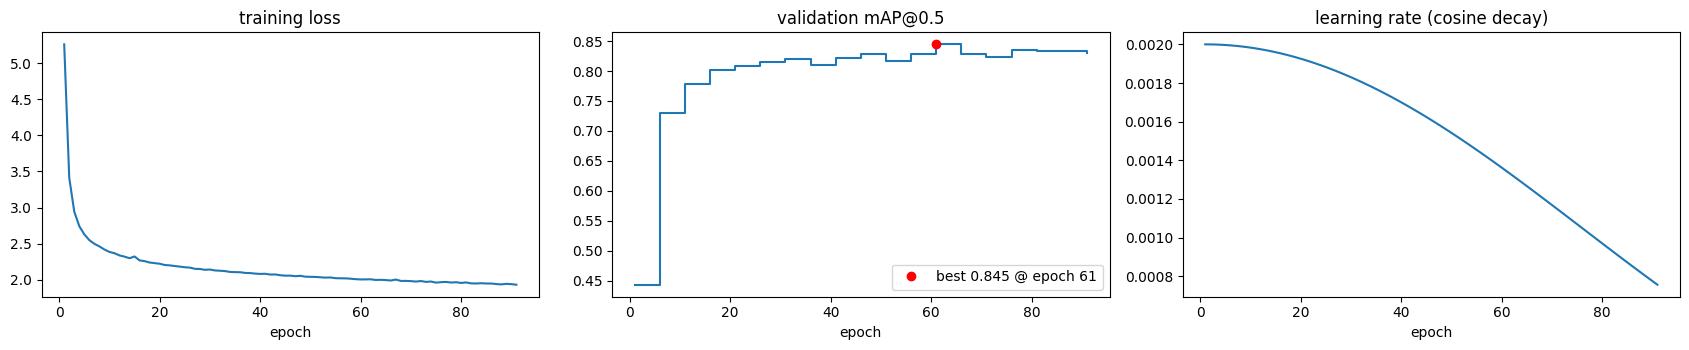

epochs run: 91 of 150; best validation mAP@0.5 = 0.8446


In [20]:
h = hist.history
ep = np.arange(1, len(h["loss"]) + 1)
planned = 2 if SMOKE else TRAIN["epochs"]
steps = max(1, int(np.ceil(len(splits["train"]) / TRAIN["batch"])))
sched = keras.optimizers.schedules.CosineDecay(TRAIN["lr"], decay_steps=planned * steps, alpha=0.05)
lr_curve = [float(sched(e * steps)) for e in range(len(ep))]
vm = np.array(h.get("val_map50", [np.nan] * len(ep)), float)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
axes[0].plot(ep, h["loss"]); axes[0].set(title="training loss", xlabel="epoch")
axes[1].step(ep, vm, where="post")
if np.isfinite(vm).any():
    b = int(np.nanargmax(vm)); axes[1].plot(ep[b], vm[b], "o", c="r", label=f"best {vm[b]:.3f} @ epoch {ep[b]}")
    axes[1].legend()
axes[1].set(title="validation mAP@0.5", xlabel="epoch")
axes[2].plot(ep, lr_curve); axes[2].set(title="learning rate (cosine decay)", xlabel="epoch")
plt.tight_layout(); savefig(fig, "c_training_curves"); plt.show()
print(f"epochs run: {len(ep)} of {planned}; best validation mAP@0.5 = {best_val_map50:.4f}")

## Test-set evaluation (float and int8) and export

The test set is used **once**, here. The float model is saved as `.keras`, exported to int8
TFLite, and both are scored on the test set. Quantisation must not cost much accuracy, or the
latency win is meaningless. The int8 model's latency is then benchmarked and everything is
written to `tiny_yolo_w1_metrics.json` for notebook 14's table.

Two ways to read the test set:
- **As deployed** (`test_float`, `test_int8`, and everything in Part D): close-ups shrunk to
  face-crop size (`closeup_eval_view`), decoded with the eye-box filter cv-argus applies.
- **Like-for-like with the 2026-10-20 run** (`test_int8_like_for_like`, printed once): the
  as-built test set (`splits_raw["test"]`, close-ups un-shrunk) decoded with
  `eye_filter=False`, the way that run's mAP@0.5 0.756 was measured. Only this one is comparable
  with the numbers in `src/cv-argus/src/constants.py`.

In [21]:
NAME = model.name
test_df = splits["test"]
keras_path = f"{models_folder}/{NAME}_{VERSION_STR}.keras"
model.save(keras_path)
preds_float = predict_keras(model, test_df, grid_postprocess)
test_float = report(preds_float, test_df, f"{NAME} / TEST float")
tflite_path = export_tflite_int8(model, f"{models_folder}/{NAME}_{VERSION_STR}_int8.tflite")
preds_int8 = predict_tflite(tflite_path, test_df, grid_postprocess)
test_int8 = report(preds_int8, test_df, f"{NAME} / TEST int8")
latency = bench_tflite(tflite_path)

# Like-for-like with the deployed 2026-10-20 run (int8 mAP@0.5 0.756): the as-built test set
# (close-ups not shrunk) and no eye-box filter, the way that run was scored.
decode_no_filter = lambda r: grid_postprocess(r, eye_filter=False)   # noqa: E731
test_int8_like_for_like = report(
    predict_tflite(tflite_path, splits_raw["test"], decode_no_filter), splits_raw["test"],
    f"{NAME} / TEST int8, LIKE-FOR-LIKE with the 2026-10-20 run (as-built test set, eye_filter=False; "
    f"that run: mAP@0.5 0.756)")

save_metrics(
    NAME, "12_tiny_grid_detector",
    params=int(model.count_params()), int8_kb=round(os.path.getsize(tflite_path) / 1024, 1),
    val_map50=best_val_map50, train_setup=TRAIN,
    test_float=test_float, test_int8=test_int8, test_int8_like_for_like=test_int8_like_for_like,
    scoring={"test_float/test_int8": "close-ups shrunk (closeup_eval_view), eye_filter=True",
             "test_int8_like_for_like": "as-built test set, eye_filter=False"},
    latency_ms=latency, keras_path=keras_path, tflite_path=tflite_path)

== tiny_yolo_w1 / TEST float
                 mAP50  mAP50-95  AP50 open_eye  AP50 closed_eye  AP50 yawn  AP50 head_straight  AP50 head_down  eye recall  eye state acc  head recall  head acc
all              0.752     0.497          0.757            0.681      0.682                0.91            0.73       0.824          0.918        0.897     0.994
kind=closeup     0.666     0.584          0.810            0.713      0.473                 NaN             NaN       0.920          0.845        0.000     0.000
kind=face        0.774     0.445          0.767            0.761      0.705                0.91            0.73       0.772          0.965        0.897     0.994
source=mrl_eye   0.810     0.808          0.856            0.764        NaN                 NaN             NaN       1.000          0.816        0.000     0.000
source=roboflow  0.746     0.436          0.742            0.670      0.682                0.91            0.73       0.758          0.968        0.897     0.994

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


== tiny_yolo_w1 / TEST int8
                 mAP50  mAP50-95  AP50 open_eye  AP50 closed_eye  AP50 yawn  AP50 head_straight  AP50 head_down  eye recall  eye state acc  head recall  head acc
all              0.756     0.511          0.755            0.680      0.695               0.909           0.743       0.820          0.920        0.902     0.994
kind=closeup     0.668     0.587          0.811            0.720      0.473                 NaN             NaN       0.921          0.845        0.000     0.000
kind=face        0.778     0.456          0.764            0.755      0.721               0.909           0.743       0.766          0.969        0.902     0.994
source=mrl_eye   0.817     0.815          0.857            0.777        NaN                 NaN             NaN       1.000          0.816        0.000     0.000
source=roboflow  0.750     0.448          0.738            0.662      0.695               0.909           0.743       0.753          0.972        0.902     0.994


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


latency (median ms) tiny_yolo_w1_20261020_2335_int8.tflite: {'1': 1.482, '2': 1.358, '4': 2.101}
-> /content/drive/MyDrive/Argus/models/parts_det/tiny_yolo_w1_metrics.json


'/content/drive/MyDrive/Argus/models/parts_det/tiny_yolo_w1_metrics.json'

# Part D: Results

How `tiny_yolo_w1` predicts on the held-out **test** set, float and int8.

**Detection confusion matrix.** A detector's errors aren't only "wrong class", so the matrix has
an extra **background** row and column:
- predictions are kept at `score ≥ CONF_THR` (the same operating point as the P/R numbers);
- each ground-truth box is matched to at most one prediction with IoU ≥ 0.5, preferring a
  same-class prediction, then the highest IoU;
- a matched pair counts in *(true class, predicted class)*;
- an unmatched ground-truth box is a **miss**: *(true class, background)*;
- an unmatched prediction is a **false alarm**: *(background, predicted class)*.

The row-normalised panel's diagonal is per-class **recall** at `CONF_THR`. For the drowsiness
rules, the cells that matter most are `closed_eye → open_eye` (a missed closure) and
`head_down → head_straight` (a missed nod).

In [22]:
def detection_confusion(preds, gts, conf=CONF_THR, iou_thr=0.5):
    """(NUM_CLASSES + 1)² counts; the last row/column is background (see the markdown)."""
    n = NUM_CLASSES
    cm = np.zeros((n + 1, n + 1), np.int64)
    for iid, (gb, gc) in gts.items():
        pb, ps, pc = preds.get(iid, (np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)))
        keep = ps >= conf
        pb, pc = pb[keep], pc[keep]
        ious = iou_xyxy(gb, pb)
        g_used, p_used = np.zeros(len(gb), bool), np.zeros(len(pb), bool)
        pairs = [(gi, pi) for gi, pi in zip(*np.where(ious >= iou_thr))] if ious.size else []
        for gi, pi in sorted(pairs, key=lambda t: (gc[t[0]] != pc[t[1]], -ious[t])):
            if not g_used[gi] and not p_used[pi]:
                g_used[gi] = p_used[pi] = True
                cm[gc[gi], pc[pi]] += 1
        for gi in np.where(~g_used)[0]:
            cm[gc[gi], n] += 1
        for pi in np.where(~p_used)[0]:
            cm[n, pc[pi]] += 1
    return cm


def plot_confusion(cm, title):
    labels = CLASSES + ["background"]
    rows = cm.sum(axis=1, keepdims=True)
    norm = np.divide(cm, rows, out=np.zeros_like(cm, dtype=float), where=rows > 0)
    norm[-1] = 0                                  # background row has no "total" to normalise by
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
    for ax, data, fmt, sub in ((axes[0], cm, "d", "counts"), (axes[1], norm, ".2f", "row-normalised (recall)")):
        shown = data.astype(float).copy(); shown[-1, -1] = np.nan
        ax.imshow(shown, cmap="Blues")
        for i in range(len(labels)):
            for j in range(len(labels)):
                if i == j == len(labels) - 1 or (sub != "counts" and i == len(labels) - 1):
                    continue
                v = data[i, j]
                ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=8,
                        color="white" if (v / (data[:-1].max() or 1)) > 0.5 else "black")
        ax.set(xticks=range(len(labels)), yticks=range(len(labels)), xlabel="predicted", ylabel="true",
               title=f"{title}: {sub}")
        ax.set_xticklabels(labels, rotation=30, ha="right"); ax.set_yticklabels(labels)
    plt.tight_layout()
    return fig


def per_class_table(preds, df, cm):
    ev = evaluate(preds, gts_for(df))
    rows = {}
    for i, c in enumerate(CLASSES):
        p, r = ev["pr_at_conf"][c]["precision"], ev["pr_at_conf"][c]["recall"]
        rows[c] = {"GT boxes": int(cm[i].sum()), "AP50": ev["ap50"][c], "P": p, "R": r,
                   "F1": 2 * p * r / max(p + r, 1e-9),
                   "missed": int(cm[i, -1]), "false alarms": int(cm[-1, i]),
                   "wrong class": int(cm[i, :-1].sum() - cm[i, i])}
    return ev, pd.DataFrame(rows).T


def image_errors(preds, gts):
    """Per image: misses + false alarms + wrong-class matches at CONF_THR."""
    out = {}
    for iid, g in gts.items():
        cm = detection_confusion(preds, {iid: g})
        out[iid] = int(cm.sum() - np.trace(cm[:-1, :-1]))
    return out


def pick_examples(df, preds, n_per_class=2, n_worst=6):
    ids = []
    for i in range(NUM_CLASSES):
        cand = df[df.classes.apply(lambda a: bool((a == i).any())) & ~df.image_id.isin(ids)]
        ids += list(cand.sample(min(n_per_class, len(cand)), random_state=SEED).image_id)
    errs = image_errors(preds, gts_for(df))
    worst = [iid for iid, e in sorted(errs.items(), key=lambda t: -t[1]) if e > 0 and iid not in ids]
    return ids, worst[:n_worst], errs


def show_pred_vs_label(models_preds, df, ids, errs=None, title="", pairs_per_row=None):
    """One column of ground truth plus one per model in `models_preds` ({name: preds})."""
    by_id = df.set_index("image_id", drop=False)
    names = list(models_preds)
    per_img = 1 + len(names)
    per_row = pairs_per_row or max(1, 8 // per_img)
    n_rows = int(np.ceil(len(ids) / per_row))
    fig, axes = plt.subplots(n_rows, per_row * per_img, figsize=(2.1 * per_row * per_img, 2.4 * n_rows),
                             squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for k, iid in enumerate(ids):
        r = by_id.loc[iid]
        img = load_rgb(r)
        row, col = divmod(k, per_row)
        col *= per_img
        e = f" · {errs[iid]} err" if errs and iid in errs else ""
        draw_boxes(axes[row, col], img, gt_xyxy(r), r["classes"], title=f"LABEL{e}\n{r['project']}")
        for m, name in enumerate(names):
            pb, ps, pc = models_preds[name].get(iid, (np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)))
            k_ = ps >= CONF_THR
            draw_boxes(axes[row, col + 1 + m], img, pb[k_], pc[k_], ps[k_], title=f"PRED {name}")
    fig.suptitle(title, y=1.0)
    plt.tight_layout()
    return fig



def pr_points(preds, gts, cls, iou_thr=0.5):
    """Scores, TP flags and n_gt for one class, matched like `average_precision` at one IoU."""
    scores, tps, n_gt = [], [], 0
    for iid, (gb, gc) in gts.items():
        g = gb[gc == cls]; n_gt += len(g)
        pb, ps, pc = preds.get(iid, (np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)))
        m = pc == cls
        pb, ps = pb[m], ps[m]
        order = np.argsort(-ps); pb, ps = pb[order], ps[order]
        ious = iou_xyxy(pb, g); used = np.zeros(len(g), bool)
        for k in range(len(pb)):
            j = int(np.argmax(ious[k])) if len(g) else -1
            hit = j >= 0 and ious[k, j] >= iou_thr and not used[j]
            if hit:
                used[j] = True
            scores.append(ps[k]); tps.append(hit)
    return np.array(scores), np.array(tps, bool), n_gt

## D1. Per-class numbers: AP, precision, recall, F1 (float vs int8)

AP50 is threshold-free. P / R / F1 are at `CONF_THR`, like the confusion matrix. "missed",
"false alarms" and "wrong class" come straight from the matrix. The second table splits the
headline numbers by `kind` and `source`, because MRL close-ups are easy and must not hide weak
face-crop results.

== tiny_yolo_w1 / TEST float
               GT boxes   AP50      P      R     F1  missed  false alarms  wrong class
open_eye         5555.0  0.757  0.870  0.729  0.793  1042.0         560.0        466.0
closed_eye       2618.0  0.681  0.713  0.833  0.769   400.0         391.0         36.0
yawn              351.0  0.682  0.705  0.755  0.729    70.0         111.0         16.0
head_straight    1200.0  0.910  0.795  0.913  0.850    95.0         281.0          9.0
head_down         122.0  0.730  0.675  0.680  0.678    29.0          35.0         10.0

== tiny_yolo_w1 / TEST int8
               GT boxes   AP50      P      R     F1  missed  false alarms  wrong class
open_eye         5555.0  0.755  0.867  0.727  0.791  1066.0         573.0        450.0
closed_eye       2618.0  0.680  0.717  0.830  0.769   406.0         390.0         38.0
yawn              351.0  0.695  0.724  0.726  0.725    80.0          97.0         16.0
head_straight    1200.0  0.909  0.792  0.915  0.849    94.0         286.

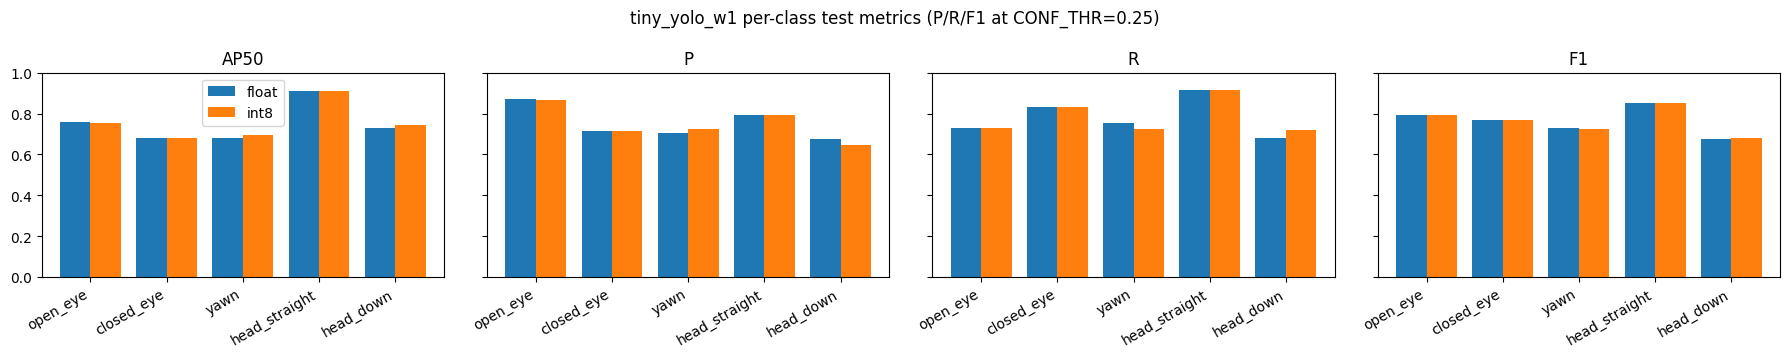


int8, by kind / source:
                 mAP50  mAP50-95  eye recall  eye state acc  head recall  head acc
all              0.756     0.511       0.820          0.920        0.902     0.994
kind=closeup     0.668     0.587       0.921          0.845        0.000     0.000
kind=face        0.778     0.456       0.766          0.969        0.902     0.994
source=mrl_eye   0.817     0.815       1.000          0.816        0.000     0.000
source=roboflow  0.750     0.448       0.753          0.972        0.902     0.994


In [23]:
gts_test = gts_for(test_df)
cm_float = detection_confusion(preds_float, gts_test)
cm_int8 = detection_confusion(preds_int8, gts_test)
ev_float, tab_float = per_class_table(preds_float, test_df, cm_float)
ev_int8, tab_int8 = per_class_table(preds_int8, test_df, cm_int8)
print(f"== {NAME} / TEST float"); print(tab_float.round(3).to_string())
print(f"\n== {NAME} / TEST int8"); print(tab_int8.round(3).to_string())

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
x = np.arange(NUM_CLASSES)
for ax, col in zip(axes, ("AP50", "P", "R", "F1")):
    ax.bar(x - 0.2, tab_float[col].astype(float), 0.4, label="float")
    ax.bar(x + 0.2, tab_int8[col].astype(float), 0.4, label="int8")
    ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=30, ha="right"); ax.set_title(col); ax.set_ylim(0, 1)
axes[0].legend()
fig.suptitle(f"{NAME} per-class test metrics (P/R/F1 at CONF_THR={CONF_THR})"); plt.tight_layout()
savefig(fig, "d1_per_class_metrics"); plt.show()

breakdown = pd.DataFrame({k: {"mAP50": r["map50"], "mAP50-95": r["map50_95"],
                              "eye recall": r["eye"]["recall"], "eye state acc": r["eye"]["state_acc"],
                              "head recall": r["head"]["recall"], "head acc": r["head"]["state_acc"]}
                          for k, r in test_int8.items()}).T
print("\nint8, by kind / source:"); print(breakdown.round(3).to_string())

## D2. Confusion matrices over all labels (float and int8)

-> /content/drive/MyDrive/Argus/models/parts_det/figures/d2_confusion_float_20261020_2335.png


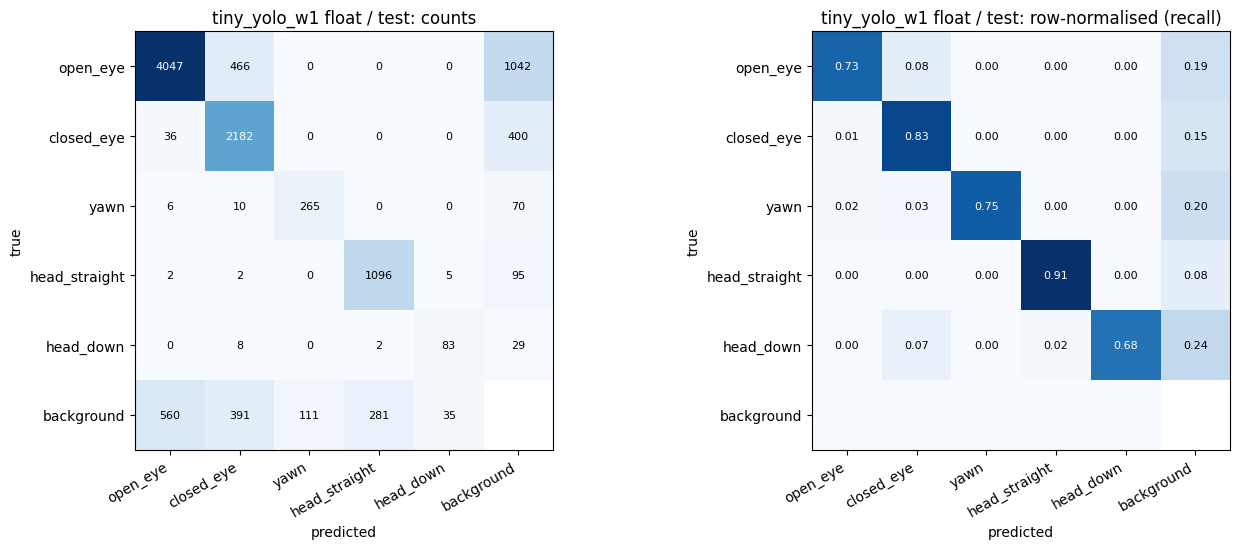

-> /content/drive/MyDrive/Argus/models/parts_det/figures/d2_confusion_int8_20261020_2335.png


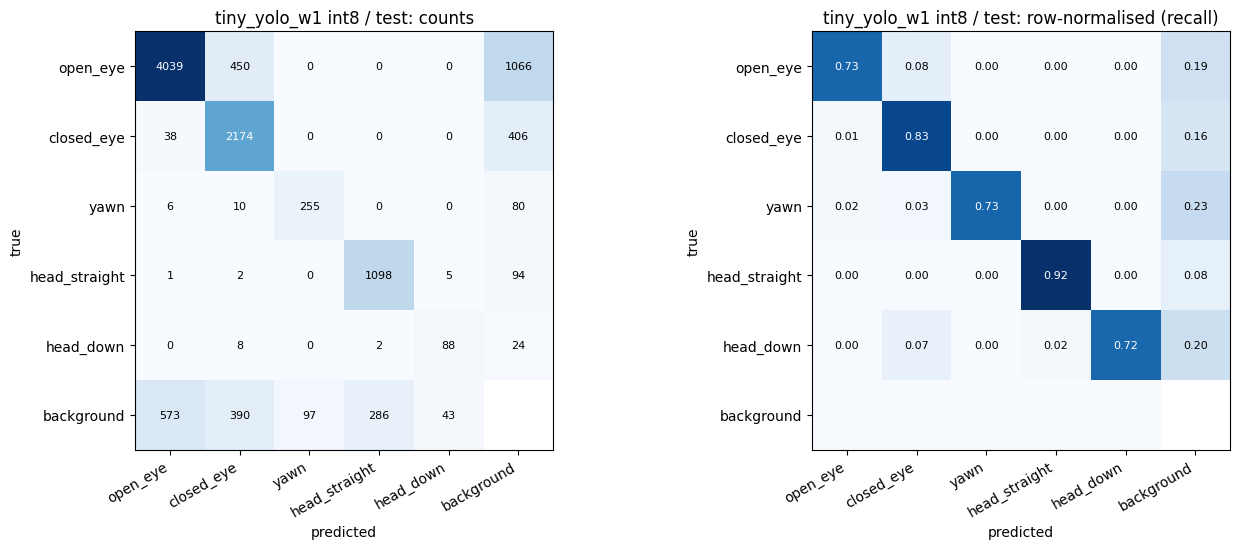

In [24]:
fig = plot_confusion(cm_float, f"{NAME} float / test"); savefig(fig, "d2_confusion_float"); plt.show()
fig = plot_confusion(cm_int8, f"{NAME} int8 / test"); savefig(fig, "d2_confusion_int8"); plt.show()

## D3. Precision–recall curves and score distributions

- **PR curve per class** (int8, IoU ≥ 0.5). The dot is the `CONF_THR` operating point. A curve
  that stays high to the right is a class the detector both finds and gets right.
- **Score histograms of true vs false positives.** Where they overlap is where no threshold
  separates hits from mistakes; that overlap sets how good `CONF_THR` can be.

-> /content/drive/MyDrive/Argus/models/parts_det/figures/d3_pr_curves_20261020_2335.png


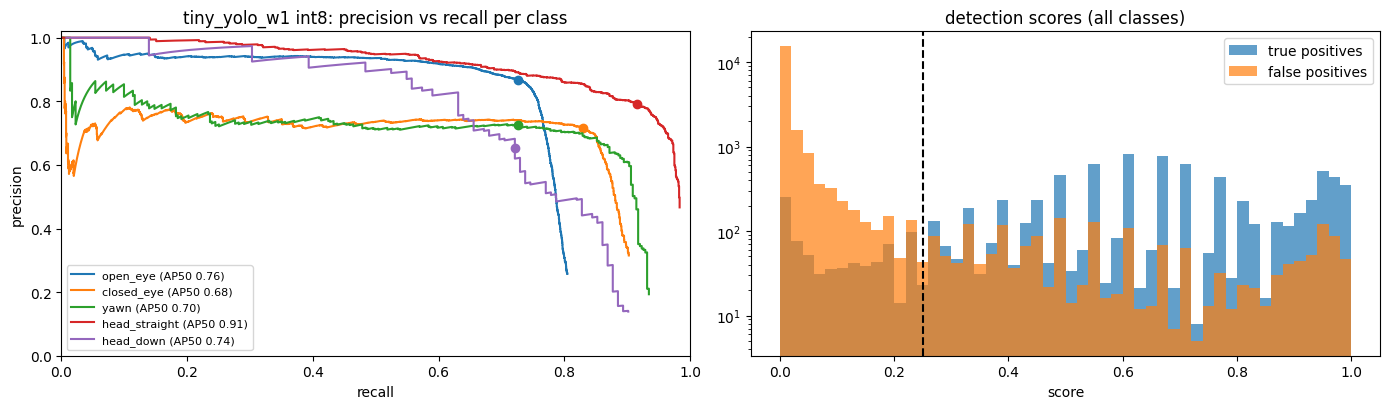

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
all_s, all_tp = [], []
for i, c in enumerate(CLASSES):
    s, tp, n_gt = pr_points(preds_int8, gts_test, i)
    if n_gt == 0 or len(s) == 0:
        continue
    order = np.argsort(-s); s, tp = s[order], tp[order]
    ctp, cfp = np.cumsum(tp), np.cumsum(~tp)
    rec, prec = ctp / n_gt, ctp / np.maximum(ctp + cfp, 1)
    axes[0].plot(rec, prec, color=CLASS_COLORS[i], label=f"{c} (AP50 {ev_int8['ap50'][c]:.2f})")
    k = np.searchsorted(-s, -CONF_THR)
    if 0 < k <= len(rec):
        axes[0].plot(rec[k - 1], prec[k - 1], "o", color=CLASS_COLORS[i])
    all_s.append(s); all_tp.append(tp)
axes[0].set(title=f"{NAME} int8: precision vs recall per class", xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8)
if all_s:
    s, tp = np.concatenate(all_s), np.concatenate(all_tp)
    axes[1].hist(s[tp], bins=50, range=(0, 1), alpha=0.7, label="true positives")
    axes[1].hist(s[~tp], bins=50, range=(0, 1), alpha=0.7, label="false positives")
    axes[1].axvline(CONF_THR, ls="--", c="k"); axes[1].set_yscale("log")
    axes[1].set(title="detection scores (all classes)", xlabel="score"); axes[1].legend()
plt.tight_layout(); savefig(fig, "d3_pr_curves"); plt.show()

## D4. Labelled vs predicted images

Each pair is the same image: the **label** on the left, the model's predictions at `CONF_THR`
on the right.
1. **Test images, a few per class.**
2. **The test images with the most errors** (misses + false alarms + wrong classes). These are
   the ones worth reading.
3. **Training images.** If the model is wrong even on images it trained on, it's underfitting
   (capacity or labels). If it's right there but wrong on test, it's not generalising.
4. **Float vs int8 on the same images.** They should look alike.

-> /content/drive/MyDrive/Argus/models/parts_det/figures/d4_test_pred_vs_label_20261020_2335.png


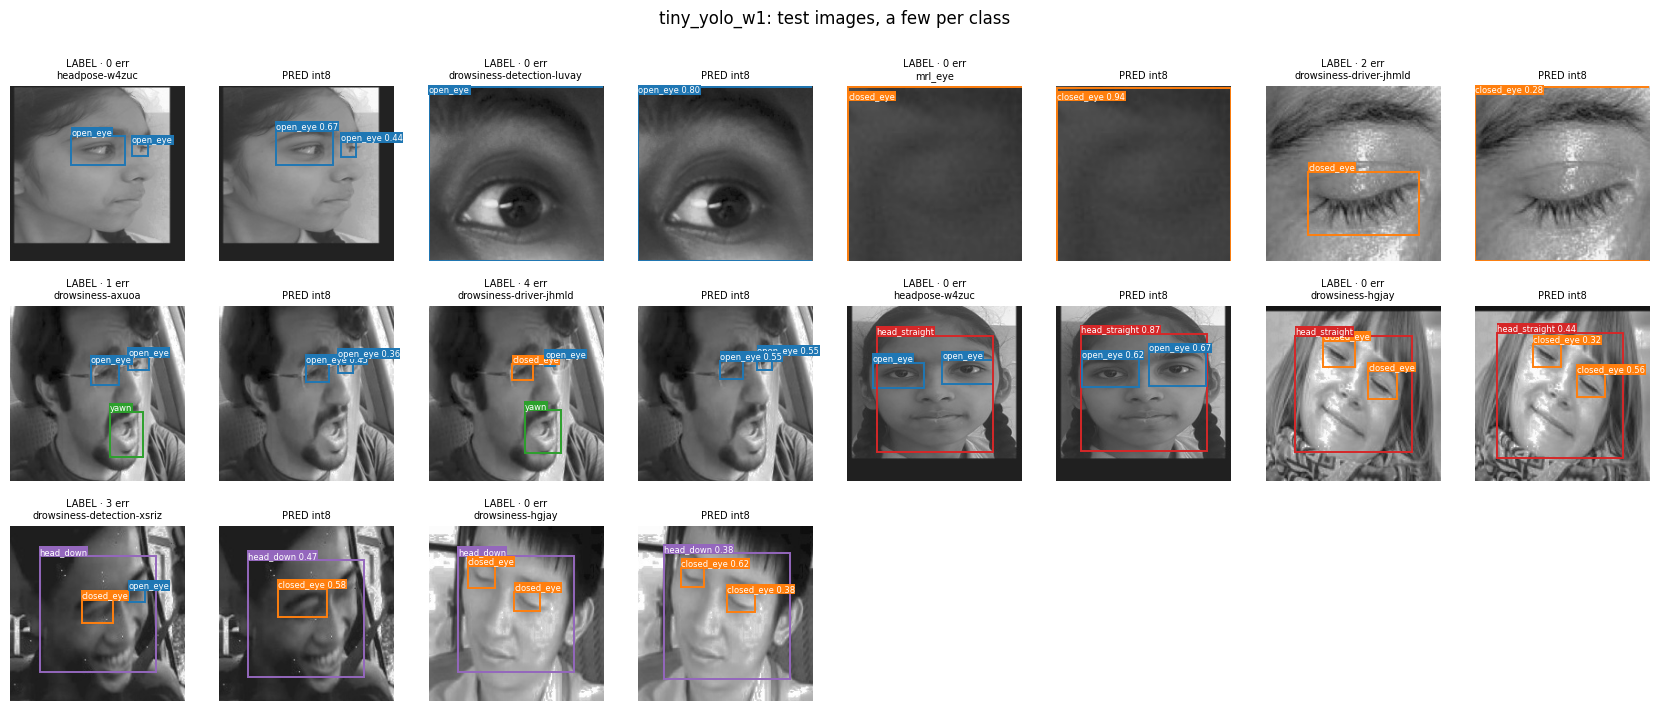

-> /content/drive/MyDrive/Argus/models/parts_det/figures/d4_test_worst_20261020_2335.png


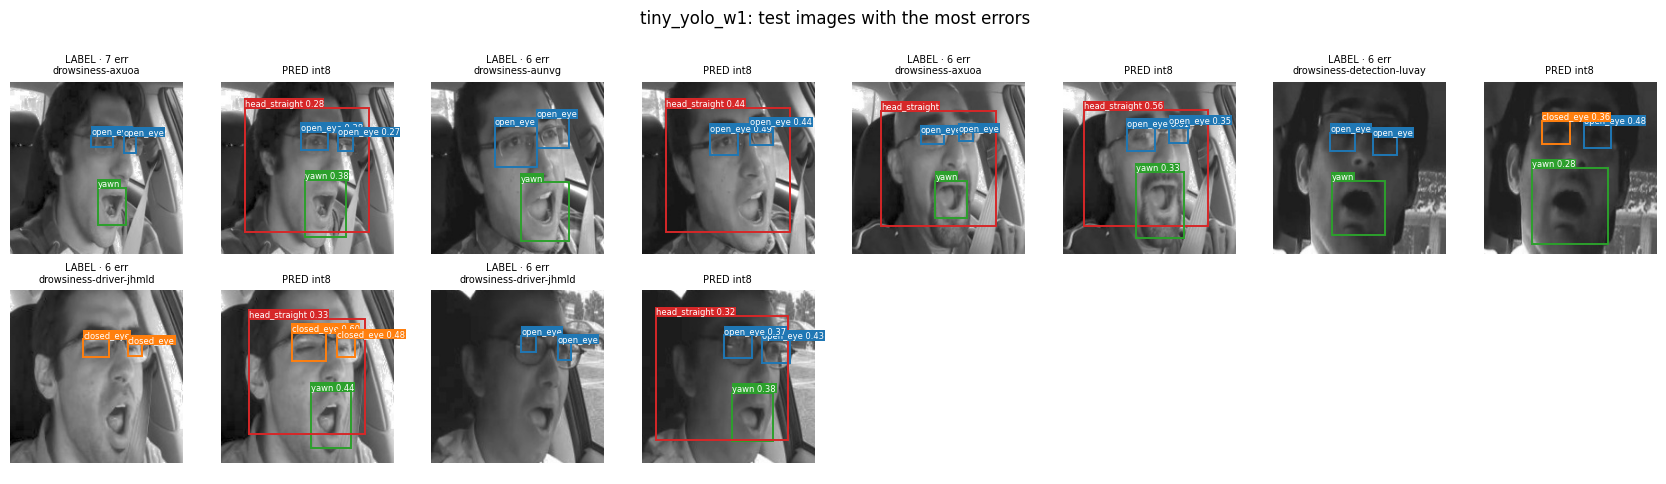

-> /content/drive/MyDrive/Argus/models/parts_det/figures/d4_train_pred_vs_label_20261020_2335.png


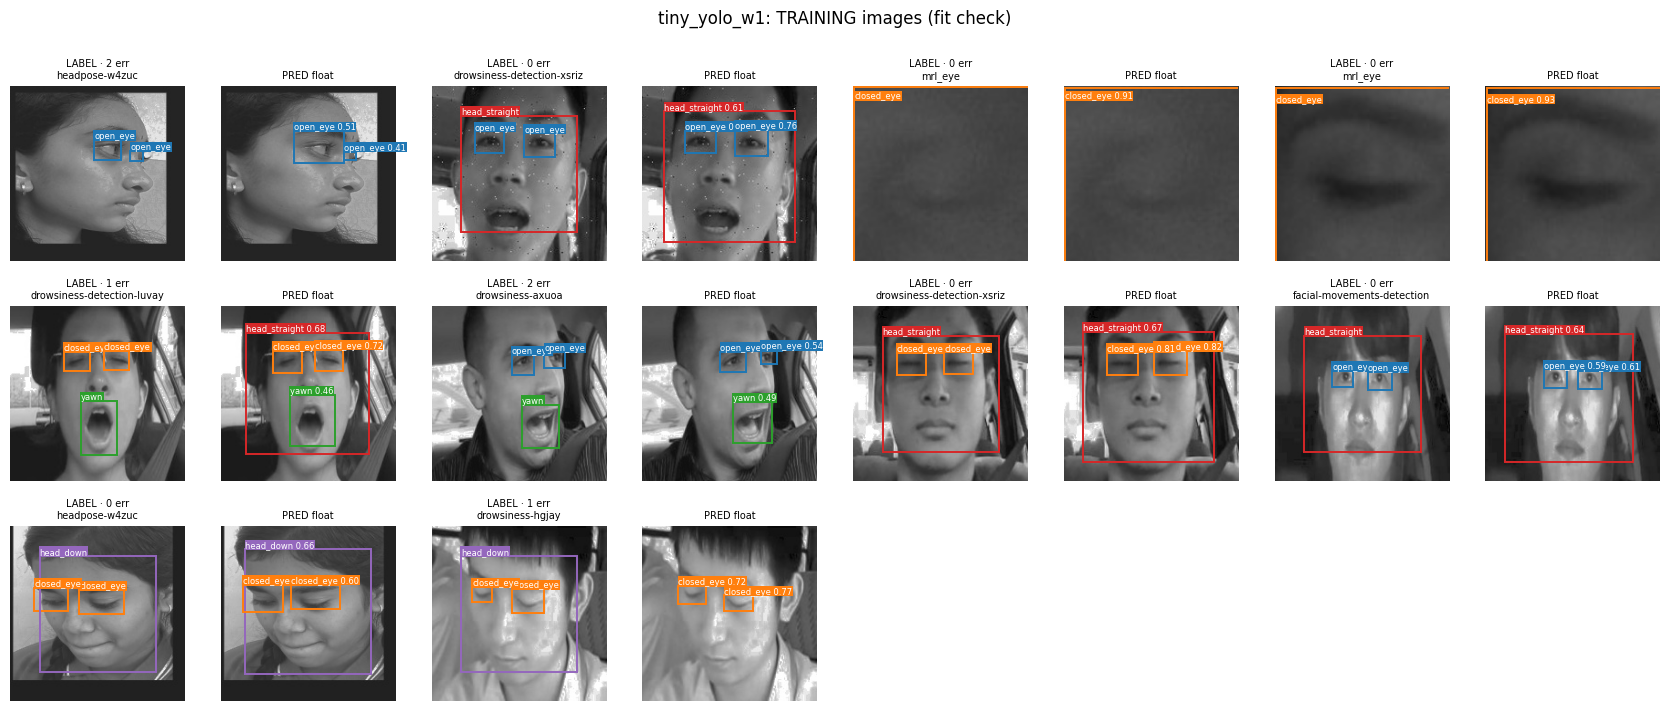

-> /content/drive/MyDrive/Argus/models/parts_det/figures/d4_float_vs_int8_20261020_2335.png


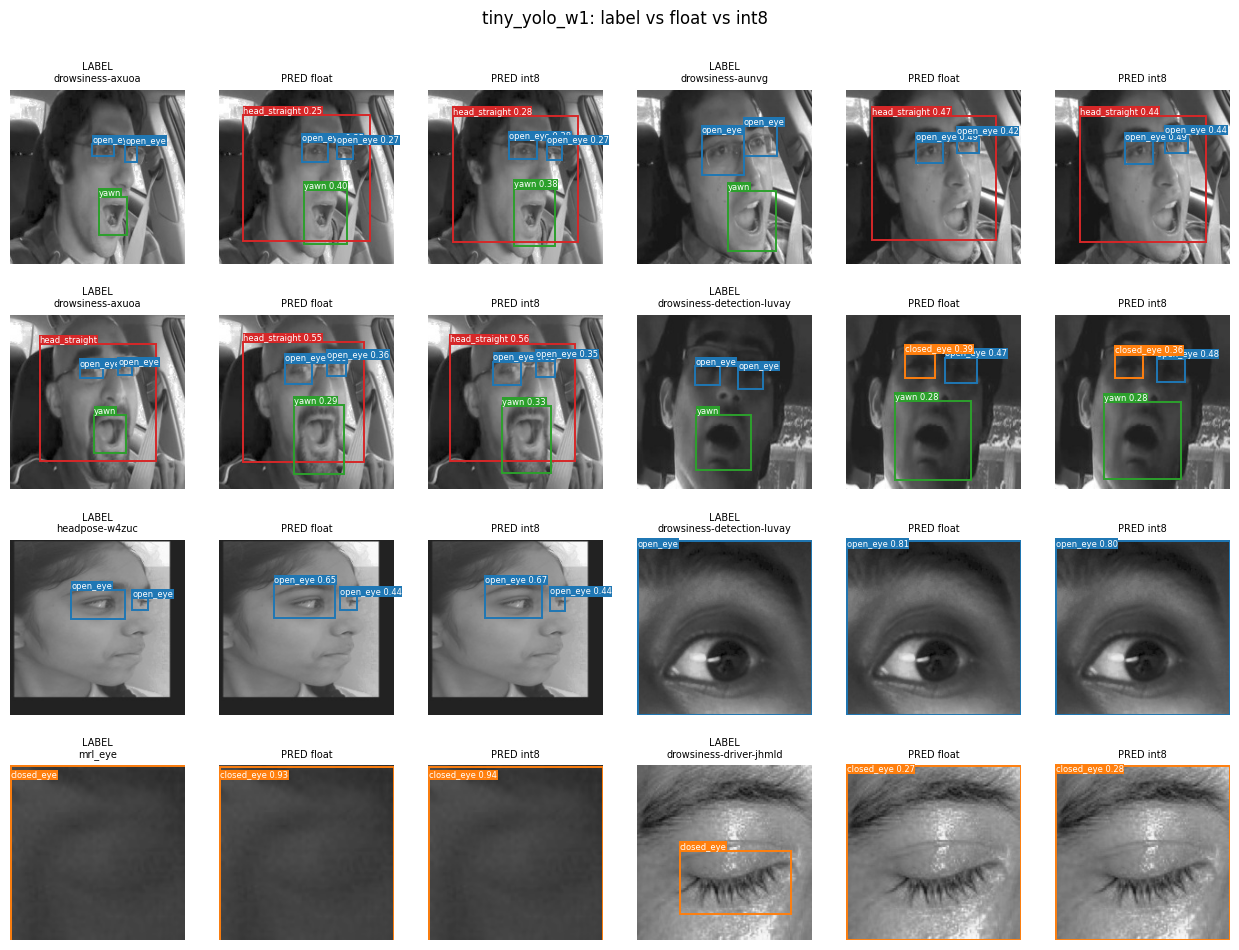

In [26]:
ids, worst, errs = pick_examples(test_df, preds_int8)
fig = show_pred_vs_label({"int8": preds_int8}, test_df, ids, errs, f"{NAME}: test images, a few per class")
savefig(fig, "d4_test_pred_vs_label"); plt.show()
if worst:
    fig = show_pred_vs_label({"int8": preds_int8}, test_df, worst, errs, f"{NAME}: test images with the most errors")
    savefig(fig, "d4_test_worst"); plt.show()

train_pick = pd.concat([splits["train"][splits["train"].classes.apply(lambda a, i=i: bool((a == i).any()))]
                        .sample(min(2, len(splits["train"])), random_state=SEED) for i in range(NUM_CLASSES)
                        if splits["train"].classes.apply(lambda a, i=i: bool((a == i).any())).any()]).drop_duplicates("image_id")
preds_train = predict_keras(model, train_pick, grid_postprocess)
fig = show_pred_vs_label({"float": preds_train}, train_pick, list(train_pick.image_id),
                         image_errors(preds_train, gts_for(train_pick)), f"{NAME}: TRAINING images (fit check)")
savefig(fig, "d4_train_pred_vs_label"); plt.show()

cmp_ids = (worst[:4] + ids[:4])[:8]
if cmp_ids:
    fig = show_pred_vs_label({"float": preds_float, "int8": preds_int8}, test_df, cmp_ids,
                             title=f"{NAME}: label vs float vs int8", pairs_per_row=2)
    savefig(fig, "d4_float_vs_int8"); plt.show()

## D5. Conclusion: this run vs. the deployed model

cv-argus deploys the `tiny_yolo_w1` trained 2026-10-20 23:35. Its int8 test numbers were mAP@0.5
0.756, eye-state accuracy 0.920, `head_down` AP@0.5 0.743 and head accuracy 0.994
(`src/cv-argus/src/constants.py`). They were measured on the as-built test set with no eye-box
filter, so the comparable column here is **this run, like-for-like** (cell 48). The **as
deployed** column (close-ups shrunk, eye filter on) is how this run's model will actually be
scored on the Pi; it has no 2026-10-20 counterpart.

The questions: does the like-for-like mAP hold up while the close-up shrink removes the
head-sized "eyes"? And does the as-deployed eye-state accuracy on `kind=closeup` now look like
`kind=face`'s?

In [27]:
prev = {"mAP50": 0.756, "eye state acc": 0.920, "AP50 head_down": 0.743, "head acc": 0.994}


def _summary(r):
    a = r["all"]
    return {"mAP50": a["map50"], "eye state acc": a["eye"]["state_acc"], "AP50 head_down": a["ap50"]["head_down"],
            "head acc": a["head"]["state_acc"], "mAP50-95": a["map50_95"]}


cols = {"deployed (2026-10-20), int8": pd.Series(prev),
        "this run, int8, like-for-like": pd.Series(_summary(test_int8_like_for_like)),
        "this run, int8, as deployed": pd.Series({
            **_summary(test_int8),
            "recall head_down @conf": tab_int8.loc["head_down", "R"],
            "recall closed_eye @conf": tab_int8.loc["closed_eye", "R"]}),
        "this run, float, as deployed": pd.Series({
            **_summary(test_float),
            "recall head_down @conf": tab_float.loc["head_down", "R"],
            "recall closed_eye @conf": tab_float.loc["closed_eye", "R"]})}
summary_tbl = pd.DataFrame(cols).reindex(list(cols["this run, int8, as deployed"].index))
print(summary_tbl.round(3).to_string())
for k in ("kind=face", "kind=closeup"):
    if k in test_int8:
        e = test_int8[k]["eye"]
        print(f"as deployed, {k}: eye recall {e['recall']:.3f}, eye state acc {e['state_acc']:.3f} (n={e['n']})")
print(f"\nmodel: {NAME}, {model.count_params():,} params, int8 {os.path.getsize(tflite_path) / 1024:.1f} KB, "
      f"latency (median ms by threads) {latency}")
print(f"saved: {keras_path}\n       {tflite_path}\nfigures: {FIG_DIR}")

                         previous (2026-10-18)  this run, float  this run, int8
mAP50                                     0.63            0.752           0.756
eye state acc                             0.95            0.918           0.920
AP50 head_down                            0.25            0.730           0.743
mAP50-95                                   NaN            0.497           0.511
head acc                                   NaN            0.994           0.994
recall head_down @conf                     NaN            0.680           0.721
recall closed_eye @conf                    NaN            0.833           0.830

model: tiny_yolo_w1, 46,026 params, int8 99.1 KB, latency (median ms by threads) {'1': 1.482, '2': 1.358, '4': 2.101}
saved: /content/drive/MyDrive/Argus/models/parts_det/tiny_yolo_w1_20261020_2335.keras
       /content/drive/MyDrive/Argus/models/parts_det/tiny_yolo_w1_20261020_2335_int8.tflite
figures: /content/drive/MyDrive/Argus/models/parts_det/figures


## Download the results (only when not saving to Drive)

With `USE_DRIVE = False`, the models and metrics live only on this session's disk and vanish
when it ends. This cell zips `models/parts_det/` and downloads it to your computer. With Drive
on, it does nothing, because the files are already in `MyDrive/Argus/models/parts_det/`.

**Shared verbatim by notebooks 12 / 13 / 14.**

In [28]:
if IN_COLAB and not USE_DRIVE and not SMOKE:
    from google.colab import files
    archive = shutil.make_archive(f"{WORK_DIR}/parts_det_results_{VERSION_STR}", "zip", models_folder)
    files.download(archive)
else:
    print(f"results are in {models_folder}")

results are in /content/drive/MyDrive/Argus/models/parts_det
